# Pipeline Step 4: Modeling and Evaluation

## Inputs
- **Final Latent Features Dataset**: `latent_only_xg_input.csv` (from Notebook 3)
- **Augmented Joined Dataset**: `final_total_input.xlsx` (from Notebook 3)
- **Official Test Set xG**: `24-25_cleaned_test.csv` (for final model benchmarking)

## Outputs
- **Saved Models**: Calibrated XGBoost and MLP models saved to the output directory
- **Model Predictions**: NPY predictions for baseline, direct classifiers, residual regressors, and meta models
- **Evaluation Visualizations**: Calibration curves, metric comparisons, subgroup breakdowns, and accumulated xG charts


### Configuration and Imports
Import required libraries for training machine learning models, cross-validation, metrics calculation, and plotting. Define temporal split date (`2025-01-07`) and save directories.

In [1]:
## Cell 1 — Imports & Configuration```python
# ============================================================
# CELL 1 — Imports & Configuration
# ============================================================

import pandas as pd
import numpy as np
from scipy.special import logit, expit  # logit = log(p/1-p), expit = sigmoid

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, GridSearchCV, StratifiedGroupKFold, GroupKFold
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
from xgboost import XGBClassifier, XGBRegressor

import warnings
import os

SAVE_DIR = os.getenv('XG_SAVE_DIR', './outputs')
os.makedirs(SAVE_DIR, exist_ok=True)
warnings.filterwarnings('ignore')

# ── Temporal split
TARGET_DATE    = pd.to_datetime("2025-01-07")
TARGET_COLUMN  = 'is_Goal'

# ── Cross-validation
N_SPLITS       = 5
RANDOM_STATE   = 42

# ── PCA
N_PCA_COMPONENTS = 16   # per group (shooter / goalie)

# ── Logit residual clipping
# Avoids log(0) when base_xg is exactly 0 or 1
PROB_CLIP_LOW  = 1e-4
PROB_CLIP_HIGH = 1 - 1e-4

print("All imports loaded successfully.")
print(f"Train/Test split date : {TARGET_DATE.date()}")
print(f"CV folds              : {N_SPLITS}")
print(f"PCA components/group  : {N_PCA_COMPONENTS}")


# ── Custom Chronological Group Time Series Splitter
class ChronologicalGroupTimeSeriesSplit:
    def __init__(self, n_splits=5):
        self.n_splits = n_splits
        
    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits
        
    def split(self, X, y=None, groups=None):
        if groups is None:
            raise ValueError("groups (orig_id) must be provided for ChronologicalGroupTimeSeriesSplit")
            
        # Look up dates from the global train_df
        global train_df
        group_date_map = train_df.groupby('orig_id')['date'].first()
        
        # Get unique groups in this split and sort them by date
        unique_groups = pd.Series(groups).unique()
        sorted_groups = group_date_map.loc[unique_groups].sort_values().index.values
        
        n_groups = len(sorted_groups)
        part_size = n_groups // (self.n_splits + 1)
        
        splits = []
        for i in range(self.n_splits):
            train_group_end = (i + 1) * part_size
            val_group_end = (i + 2) * part_size if i < self.n_splits - 1 else n_groups
            
            train_groups = sorted_groups[:train_group_end]
            val_groups = sorted_groups[train_group_end:val_group_end]
            
            train_idx = np.where(np.isin(groups, train_groups))[0]
            val_idx = np.where(np.isin(groups, val_groups))[0]
            
            splits.append((train_idx, val_idx))
            
        return splits


All imports loaded successfully.
Train/Test split date : 2025-01-07
CV folds              : 5
PCA components/group  : 16


### Data Loading and Integrity Checks
Load the final style and EMA datasets. Run basic integrity and shape checks to verify alignment.

In [2]:
# ============================================================
# CELL 2 — Load Data & Integrity Check
# ============================================================

# df_ema    : original shots + raw EMA performance stats (sh__pre__, gk__pre__)
# df_latent : style vectors from autoencoder (sh_style_, gk_style_)

df_ema = pd.read_excel('final_total_input_augmented.xlsx')
df_latent = pd.read_csv('latent_only_xg_input.csv')

# ── Basic integrity check ────────────────────────────────────
assert len(df_ema) == len(df_latent), (
    f"Row mismatch: df_ema={len(df_ema)}, df_latent={len(df_latent)}"
)

# ── Date format ──────────────────────────────────────────────
df_ema['date'] = pd.to_datetime(df_ema['date'])

# ── Build master dataframe ───────────────────────────────────
latent_style_cols = [c for c in df_latent.columns if 'style_' in c]

master_df = pd.concat(
    [df_ema.reset_index(drop=True),
     df_latent[latent_style_cols].reset_index(drop=True)],
    axis=1
)

# ── Remove any duplicate columns ────────────────────────────
master_df = master_df.loc[:, ~master_df.columns.duplicated()].copy()

# ── Verify target column ─────────────────────────────────────
assert TARGET_COLUMN in master_df.columns, f"Target column '{TARGET_COLUMN}' not found."

goal_rate = master_df[TARGET_COLUMN].mean()

# ── Summary ──────────────────────────────────────────────────
print("=" * 45)
print("Data loaded successfully")
print("=" * 45)
print(f"Total shots         : {len(master_df):,}")
print(f"Goal rate           : {goal_rate:.2%}")
print(f"Latent style cols   : {len(latent_style_cols)}")
print(f"Date range          : {master_df['date'].min().date()} → {master_df['date'].max().date()}")
print(f"Missing values      : {master_df.isnull().sum().sum()}")


Data loaded successfully
Total shots         : 29,678
Goal rate           : 10.28%
Latent style cols   : 32
Date range          : 2023-08-26 → 2025-05-24
Missing values      : 0


### Feature Group Definitions and Goalkeeper Artifacts Handling
Categorise physical features, raw EMA features, and latent style features. Handle goalkeeper coordinate artifacts (replacing 0,0 values with values drawn from a random normal distribution matching the valid samples).

In [3]:
# ============================================================
# CELL 3 — Define Feature Groups
# ============================================================

# ── Physical shot features ───────────────────────────────────
PHYSICAL_FEATURES = [c for c in master_df.columns if c.startswith('shots_enc__')]


# ── Handling GK Position Artifacts (Replacing 0,0 with Random Distribution) ──
gk_cols = ['shots_enc__shots__GKx', 'shots_enc__shots__GKy']

np.random.seed(42)
for col in gk_cols:
    # Identify valid (non-zero) data in train split only to avoid test leak
    train_valid = master_df[(master_df[col] != 0) & (master_df['date'] < TARGET_DATE)][col]
    missing_mask = (master_df['shots_enc__shots__GKx'] == 0) & (master_df['shots_enc__shots__GKy'] == 0)

    # Calculate stats from valid train samples
    mu, sigma = train_valid.mean(), train_valid.std()

    # Fill only the 0,0 artifacts with random values from the same distribution
    num_missing = missing_mask.sum()
    master_df.loc[missing_mask, col] = np.random.normal(mu, sigma, size=num_missing)



# ── Raw EMA features (shooter & goalie separately) ───────────
SHOOTER_EMA_FEATURES = [c for c in master_df.columns if c.startswith('sh__pre__')]
GOALIE_EMA_FEATURES  = [c for c in master_df.columns if c.startswith('gk__pre__')]
EMA_FEATURES         = SHOOTER_EMA_FEATURES + GOALIE_EMA_FEATURES

# ── Latent style features (from autoencoder) ─────────────────
SHOOTER_LATENT_FEATURES = [c for c in master_df.columns if c.startswith('sh_style_')]
GOALIE_LATENT_FEATURES  = [c for c in master_df.columns if c.startswith('gk_style_')]
LATENT_FEATURES         = SHOOTER_LATENT_FEATURES + GOALIE_LATENT_FEATURES

# ── Sanity checks ────────────────────────────────────────────
assert len(PHYSICAL_FEATURES) > 0,        "No physical features found — check prefix 'shots_enc__'"
assert len(SHOOTER_EMA_FEATURES) > 0,     "No shooter EMA features found — check prefix 'sh__pre__'"
assert len(GOALIE_EMA_FEATURES) > 0,      "No goalie EMA features found — check prefix 'gk__pre__'"
assert len(SHOOTER_LATENT_FEATURES) > 0,  "No shooter latent features found — check prefix 'sh_style_'"
assert len(GOALIE_LATENT_FEATURES) > 0,   "No goalie latent features found — check prefix 'gk_style_'"

# ── Summary ──────────────────────────────────────────────────
print("=" * 45)
print("Feature groups defined")
print("=" * 45)
print(f"Physical shot features      : {len(PHYSICAL_FEATURES)}")
print(f"Shooter EMA features        : {len(SHOOTER_EMA_FEATURES)}")
print(f"Goalie EMA features         : {len(GOALIE_EMA_FEATURES)}")
print(f"Shooter latent features     : {len(SHOOTER_LATENT_FEATURES)}")
print(f"Goalie latent features      : {len(GOALIE_LATENT_FEATURES)}")
print("-" * 45)
print(f"Total EMA features          : {len(EMA_FEATURES)}")
print(f"Total latent features       : {len(LATENT_FEATURES)}")


Feature groups defined
Physical shot features      : 49
Shooter EMA features        : 37
Goalie EMA features         : 37
Shooter latent features     : 16
Goalie latent features      : 16
---------------------------------------------
Total EMA features          : 74
Total latent features       : 32


In [4]:
# ============================================================
# CELL 4 — Temporal Train/Test Split
# ============================================================

train_df = master_df[master_df['date'] < TARGET_DATE].copy()
test_df  = master_df[master_df['date'] >= TARGET_DATE].copy()

# ── Reset indices ────────────────────────────────────────────
train_df = train_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

# Define group keys for Group-aware CV
GROUPS_TRAIN = train_df['orig_id'].values

# ── Verify no overlap ────────────────────────────────────────
assert train_df['date'].max() < test_df['date'].min(), \
    "Date overlap detected between train and test sets!"

# ── Class distribution ───────────────────────────────────────
train_goal_rate = train_df[TARGET_COLUMN].mean()
test_goal_rate  = test_df[TARGET_COLUMN].mean()

# ── Scale pos weight for XGBoost (based on train only) ───────
SCALE_POS_WEIGHT = (train_df[TARGET_COLUMN] == 0).sum() / train_df[TARGET_COLUMN].sum()

# ── Summary ──────────────────────────────────────────────────
print("=" * 45)
print("Temporal split complete")
print("=" * 45)
print(f"Train set size      : {len(train_df):,} shots")
print(f"Test set size       : {len(test_df):,} shots")
print(f"Train date range    : {train_df['date'].min().date()} → {train_df['date'].max().date()}")
print(f"Test date range     : {test_df['date'].min().date()} → {test_df['date'].max().date()}")
print("-" * 45)
print(f"Train goal rate     : {train_goal_rate:.2%}")
print(f"Test goal rate      : {test_goal_rate:.2%}")
print(f"Scale pos weight    : {SCALE_POS_WEIGHT:.2f}")


Temporal split complete
Train set size      : 26,790 shots
Test set size       : 2,888 shots
Train date range    : 2023-08-26 → 2025-01-06
Test date range     : 2025-01-11 → 2025-05-24
---------------------------------------------
Train goal rate     : 10.13%
Test goal rate      : 11.63%
Scale pos weight    : 8.87


### Principal Component Analysis (PCA) on EMA Features
Perform PCA on the 37 raw EMA form features separately for the shooter and goalie, retaining 16 components for each group.

In [5]:
# ============================================================
# CELL 5 — PCA on EMA Features
# ============================================================

def fit_pca_group(train_data, test_data, columns, n_components, prefix):
    """
    Fits StandardScaler + PCA on train, transforms both train and test.
    Returns transformed dataframes and the list of new column names.
    """
    scaler = StandardScaler()
    pca    = PCA(n_components=n_components)

    # Fit on train only — transform both
    train_scaled = scaler.fit_transform(train_data[columns])
    test_scaled  = scaler.transform(test_data[columns])

    train_pca = pca.fit_transform(train_scaled)
    test_pca  = pca.transform(test_scaled)

    pca_cols = [f'{prefix}_pca_{i}' for i in range(n_components)]

    train_out = pd.DataFrame(train_pca, columns=pca_cols, index=train_data.index)
    test_out  = pd.DataFrame(test_pca,  columns=pca_cols, index=test_data.index)

    variance_explained = pca.explained_variance_ratio_.sum()

    return train_out, test_out, pca_cols, variance_explained


# ── Apply PCA separately for shooter and goalie EMA ──────────
train_sh_pca, test_sh_pca, SH_PCA_COLS, sh_var = fit_pca_group(
    train_df, test_df,
    columns=SHOOTER_EMA_FEATURES,
    n_components=N_PCA_COMPONENTS,
    prefix='sh'
)

train_gk_pca, test_gk_pca, GK_PCA_COLS, gk_var = fit_pca_group(
    train_df, test_df,
    columns=GOALIE_EMA_FEATURES,
    n_components=N_PCA_COMPONENTS,
    prefix='gk'
)

# ── Merge PCA features back into train/test dataframes ───────
train_df = pd.concat([train_df, train_sh_pca, train_gk_pca], axis=1)
test_df  = pd.concat([test_df,  test_sh_pca,  test_gk_pca],  axis=1)

PCA_FEATURES = SH_PCA_COLS + GK_PCA_COLS

# ── Summary ──────────────────────────────────────────────────
print("=" * 45)
print("PCA complete")
print("=" * 45)
print(f"Shooter PCA — variance explained : {sh_var:.2%}")
print(f"Goalie  PCA — variance explained : {gk_var:.2%}")
print(f"Total PCA features added         : {len(PCA_FEATURES)}")
print(f"Train shape after PCA            : {train_df.shape}")
print(f"Test shape after PCA             : {test_df.shape}")

PCA complete
Shooter PCA — variance explained : 91.87%
Goalie  PCA — variance explained : 98.16%
Total PCA features added         : 32
Train shape after PCA            : (26790, 194)
Test shape after PCA             : (2888, 194)


### Interaction Features Definition
Define the helper function to build interaction columns between top physical features and player style representations.

In [6]:
# ============================================================
# CELL 6 — Interaction Features (Function Definition Only)
# ============================================================

# This cell only defines the function.
# It will be called after Cell 7, once we know the top physical
# features according to the base model feature importance.

def build_interaction_features(df, top_physical_cols, shooter_latent_cols, goalie_latent_cols):
    """
    Builds interaction features between the most important physical
    features and the shooter/goalie latent style vectors.

    Only used for Logistic Regression — tree-based models and MLP
    can discover interactions on their own.

    Parameters:
        df                  : dataframe (train or test)
        top_physical_cols   : top N physical features by importance
        shooter_latent_cols : shooter style vector columns
        goalie_latent_cols  : goalie style vector columns

    Returns:
        interactions_df : dataframe of interaction columns
        interaction_cols: list of new column names
    """
    frames = []
    cols   = []

    # Shooter interactions
    for ph in top_physical_cols:
        for st in shooter_latent_cols:
            frames.append((df[ph] * df[st]).rename(f'inter_sh__{ph}_x_{st}'))
            cols.append(f'inter_sh__{ph}_x_{st}')

    # Goalie interactions
    for ph in top_physical_cols:
        for gk in goalie_latent_cols:
            frames.append((df[ph] * df[gk]).rename(f'inter_gk__{ph}_x_{gk}'))
            cols.append(f'inter_gk__{ph}_x_{gk}')

    interactions_df = pd.concat(frames, axis=1)

    return interactions_df, cols

### Baseline Model Optimization (Physical Features Only)
Train an XGBoost Classifier on physical features using Stratified 5-Fold cross-validation to establish the baseline xG prediction.

In [7]:
# ============================================================
# CELL 7 — Base Model + Optimization (with OOF saving)
# ============================================================

import json


# ── Hyperparameter search ─────────────────────────────────────
param_dist = {
    'n_estimators'    : [100, 200, 300],
    'max_depth'       : [3, 4, 5],
    'learning_rate'   : [0.01, 0.05, 0.1],
    'subsample'       : [0.6, 0.7, 0.8],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [3, 5, 7],
    'reg_alpha'       : [0.0, 0.5, 1.0],
    'reg_lambda'      : [1.0, 5.0, 10.0],
}

X_train_base = train_df[PHYSICAL_FEATURES]
y_train      = train_df[TARGET_COLUMN]

base_xgb = XGBClassifier(
    objective        = 'binary:logistic',
    scale_pos_weight = SCALE_POS_WEIGHT,
    random_state     = RANDOM_STATE,
    eval_metric      = 'logloss',
    verbosity        = 0
)

cv = ChronologicalGroupTimeSeriesSplit(n_splits=N_SPLITS)

search = RandomizedSearchCV(
    base_xgb, param_dist,
    n_iter      = 30,
    scoring     = 'neg_log_loss',
    cv          = cv,
    random_state= RANDOM_STATE,
    n_jobs      = -1,
    verbose     = 1
)
search.fit(X_train_base, y_train, groups=GROUPS_TRAIN)

best_params = search.best_params_
print(f"Best params: {best_params}")

# ── OOF predictions on train set ─────────────────────────────
oof_baseline_train = np.zeros(len(train_df))

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_base, y_train, groups=GROUPS_TRAIN)):
    X_fold_train = X_train_base.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]
    X_fold_val   = X_train_base.iloc[val_idx]

    fold_model = XGBClassifier(
        **best_params,
        objective        = 'binary:logistic',
        scale_pos_weight = SCALE_POS_WEIGHT,
        random_state     = RANDOM_STATE,
        eval_metric      = 'logloss',
        verbosity        = 0
    )
    fold_model.fit(X_fold_train, y_fold_train)
    oof_baseline_train[val_idx] = fold_model.predict_proba(X_fold_val)[:, 1]
    if fold == 0:
        oof_baseline_train[train_idx] = fold_model.predict_proba(X_fold_train)[:, 1]
    print(f"  Fold {fold+1} done.")

print(f"Baseline OOF Log-Loss on train: {log_loss(y_train, oof_baseline_train):.4f}")

# ── Train final model on full train set ───────────────────────
final_base_model = XGBClassifier(
    **best_params,
    objective        = 'binary:logistic',
    scale_pos_weight = SCALE_POS_WEIGHT,
    random_state     = RANDOM_STATE,
    eval_metric      = 'logloss',
    verbosity        = 0
)
final_base_model.fit(X_train_base, y_train)

# Predict on test set
probs_baseline = final_base_model.predict_proba(
    test_df[PHYSICAL_FEATURES]
)[:, 1]

# Store base_xg in train_df for reference
train_df['base_xg'] = oof_baseline_train

# ── Evaluate on OOF train set (No Test Peeking) ────────────────
base_oof_ll    = log_loss(y_train, oof_baseline_train)
base_oof_auc   = roc_auc_score(y_train, oof_baseline_train)
base_oof_brier = brier_score_loss(y_train, oof_baseline_train)

print(f"\nBaseline OOF validation results:")
print(f"  Log-Loss : {base_oof_ll:.4f}")
print(f"  AUC      : {base_oof_auc:.4f}")
print(f"  Brier    : {base_oof_brier:.4f}")

# (Still calculate test predictions for final comparison, but do not print test metrics)
y_test = test_df[TARGET_COLUMN]
base_ll    = log_loss(y_test, probs_baseline)
base_auc   = roc_auc_score(y_test, probs_baseline)
base_brier = brier_score_loss(y_test, probs_baseline)

# ── Save ──────────────────────────────────────────────────────
np.save(f"{SAVE_DIR}/probs_baseline.npy",          probs_baseline)
np.save(f"{SAVE_DIR}/probs_baseline_oof_train.npy", oof_baseline_train)
np.save(f"{SAVE_DIR}/y_test.npy",                  y_test.values)

with open(f"{SAVE_DIR}/best_params_baseline.json", 'w') as f:
    json.dump(best_params, f)

print(f"\nSaved baseline OOF train predictions and test predictions to Drive.")

# ── Build interaction features (needs feature importance from Cell 7) ──
TOP_N = 10
top_physical = pd.Series(
    final_base_model.feature_importances_,
    index=PHYSICAL_FEATURES
).nlargest(TOP_N).index.tolist()

train_inter_df, INTERACTION_FEATURES = build_interaction_features(
    train_df, top_physical, SHOOTER_LATENT_FEATURES, GOALIE_LATENT_FEATURES
)
test_inter_df, _ = build_interaction_features(
    test_df, top_physical, SHOOTER_LATENT_FEATURES, GOALIE_LATENT_FEATURES
)

train_df = pd.concat([train_df, train_inter_df], axis=1)
test_df  = pd.concat([test_df,  test_inter_df],  axis=1)

print(f"Interaction features built: {len(INTERACTION_FEATURES)}")


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'subsample': 0.6, 'reg_lambda': 10.0, 'reg_alpha': 1.0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
  Fold 1 done.
  Fold 2 done.
  Fold 3 done.
  Fold 4 done.
  Fold 5 done.
Baseline OOF Log-Loss on train: 0.2384

Baseline OOF validation results:
  Log-Loss : 0.2384
  AUC      : 0.8951
  Brier    : 0.0679

Saved baseline OOF train predictions and test predictions to Drive.
Interaction features built: 320


### Direct Classifiers (Approach 1 & Approach 2)
Train direct classifiers (XGBoost, Logistic Regression, MLP) on:
- **Approach 1 (AP1)**: Physical + Latent style features
- **Approach 2 (AP2)**: Physical + PCA features

Apply isotonic calibration (`CalibratedClassifierCV`) to calibrate output probabilities.

In [8]:
# ============================================================
# CELL 8 — Approaches 1 & 2 with OOF saving
# ============================================================


import joblib

cv = ChronologicalGroupTimeSeriesSplit(n_splits=N_SPLITS)

AP1_FEATURES = PHYSICAL_FEATURES + LATENT_FEATURES
AP2_FEATURES = PHYSICAL_FEATURES + PCA_FEATURES

X_train_ap1 = train_df[AP1_FEATURES]
X_test_ap1  = test_df[AP1_FEATURES]
X_train_ap2 = train_df[AP2_FEATURES]
X_test_ap2  = test_df[AP2_FEATURES]
y_train     = train_df[TARGET_COLUMN]
y_test      = test_df[TARGET_COLUMN]

results_ap1_ap2 = {}

# ============================================================
# XGBoost — Approach 1 & 2
# ============================================================
param_dist_xgb = {
    'n_estimators'    : [100, 200, 300],
    'max_depth'       : [3, 4, 5],
    'learning_rate'   : [0.01, 0.05, 0.1],
    'subsample'       : [0.6, 0.7, 0.8],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [3, 5, 7],
    'reg_alpha'       : [0.0, 0.5, 1.0],
    'reg_lambda'      : [1.0, 5.0, 10.0],
}

for ap_name, X_train_ap, X_test_ap in [
    ('ap1', X_train_ap1, X_test_ap1),
    ('ap2', X_train_ap2, X_test_ap2)
]:
    print(f"\n{'='*50}")
    print(f"XGBoost — {ap_name.upper()}")
    print(f"{'='*50}")

    xgb = XGBClassifier(
        objective        = 'binary:logistic',
        scale_pos_weight = SCALE_POS_WEIGHT,
        random_state     = RANDOM_STATE,
        eval_metric      = 'logloss',
        verbosity        = 0
    )

    search = RandomizedSearchCV(
        xgb, param_dist_xgb,
        n_iter=30, scoring='neg_log_loss',
        cv=cv, random_state=RANDOM_STATE,
        n_jobs=-1, verbose=0
    )
    search.fit(X_train_ap, y_train, groups=GROUPS_TRAIN)
    best_params = search.best_params_
    print(f"Best params: {best_params}")

    # OOF
    print(f"Computing OOF for {ap_name} XGBoost...")
    oof = np.zeros(len(train_df))
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_ap, y_train, groups=GROUPS_TRAIN)):
        m = XGBClassifier(
            **best_params,
            objective        = 'binary:logistic',
            scale_pos_weight = SCALE_POS_WEIGHT,
            random_state     = RANDOM_STATE,
            eval_metric      = 'logloss',
            verbosity        = 0
        )
        m.fit(X_train_ap.iloc[train_idx], y_train.iloc[train_idx])
        oof[val_idx] = m.predict_proba(X_train_ap.iloc[val_idx])[:, 1]
        if fold == 0:
            oof[train_idx] = m.predict_proba(X_train_ap.iloc[train_idx])[:, 1]
        print(f"  Fold {fold+1} done.")
    print(f"OOF Log-Loss: {log_loss(y_train, oof):.4f}")

    # Final model + calibration
    final_model = XGBClassifier(
        **best_params,
        objective        = 'binary:logistic',
        scale_pos_weight = SCALE_POS_WEIGHT,
        random_state     = RANDOM_STATE,
        eval_metric      = 'logloss',
        verbosity        = 0
    )
    final_model.fit(X_train_ap, y_train)
    calibrated = CalibratedClassifierCV(final_model, method='isotonic', cv=3)
    calibrated.fit(X_train_ap, y_train)
    probs_test = calibrated.predict_proba(X_test_ap)[:, 1]

    # Evaluate OOF on Train
    oof_ll    = log_loss(y_train, oof)
    oof_auc   = roc_auc_score(y_train, oof)
    oof_brier = brier_score_loss(y_train, oof)
    oof_mae   = np.abs(oof - y_train.values).mean()
    print(f"OOF Train — Log-Loss: {oof_ll:.4f} | AUC: {oof_auc:.4f} | Brier: {oof_brier:.4f} | MAE: {oof_mae:.4f}")

    results_ap1_ap2[f'{ap_name}_XGBoost'] = {
        'll': oof_ll, 'auc': oof_auc, 'brier': oof_brier, 'mae': oof_mae
    }

    joblib.dump(calibrated, f"{SAVE_DIR}/model_{ap_name}_XGBoost.pkl")
    np.save(f"{SAVE_DIR}/probs_{ap_name}_XGBoost.npy",           probs_test)
    np.save(f"{SAVE_DIR}/probs_{ap_name}_XGBoost_oof_train.npy", oof)

    if ap_name == 'ap1':
        probs_ap1_xgb = probs_test

# ============================================================
# Logistic Regression — Approach 1 & 2
# ============================================================
for ap_name, X_train_ap, X_test_ap in [
    ('ap1', X_train_ap1, X_test_ap1),
    ('ap2', X_train_ap2, X_test_ap2)
]:
    print(f"\n{'='*50}")
    print(f"Logistic Regression — {ap_name.upper()}")
    print(f"{'='*50}")

    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_train_ap)
    X_te_scaled = scaler.transform(X_test_ap)

    lr = LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=RANDOM_STATE
    )
    lr.fit(X_tr_scaled, y_train)

    # OOF
    print(f"Computing OOF for {ap_name} LR...")
    oof = np.zeros(len(train_df))
    X_train_ap_arr = np.array(X_train_ap)
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_ap_arr, y_train, groups=GROUPS_TRAIN)):
        sc = StandardScaler()
        X_f_tr  = sc.fit_transform(X_train_ap_arr[train_idx])
        X_f_val = sc.transform(X_train_ap_arr[val_idx])
        m = LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=RANDOM_STATE
        )
        m.fit(X_f_tr, np.array(y_train)[train_idx])
        oof[val_idx] = m.predict_proba(X_f_val)[:, 1]
        if fold == 0:
            oof[train_idx] = m.predict_proba(X_f_tr)[:, 1]
        print(f"  Fold {fold+1} done.")
    print(f"OOF Log-Loss: {log_loss(y_train, oof):.4f}")

    probs_test = lr.predict_proba(X_te_scaled)[:, 1]
    # Evaluate OOF on Train
    oof_ll    = log_loss(y_train, oof)
    oof_auc   = roc_auc_score(y_train, oof)
    oof_brier = brier_score_loss(y_train, oof)
    oof_mae   = np.abs(oof - y_train.values).mean()
    print(f"OOF Train — Log-Loss: {oof_ll:.4f} | AUC: {oof_auc:.4f} | Brier: {oof_brier:.4f} | MAE: {oof_mae:.4f}")

    results_ap1_ap2[f'{ap_name}_LR'] = {
        'll': oof_ll, 'auc': oof_auc, 'brier': oof_brier, 'mae': oof_mae
    }

    np.save(f"{SAVE_DIR}/probs_{ap_name}_LR.npy",           probs_test)
    np.save(f"{SAVE_DIR}/probs_{ap_name}_LR_oof_train.npy", oof)

# ============================================================
# MLP — Approach 1 & 2
# ============================================================
for ap_name, X_train_ap, X_test_ap in [
    ('ap1', X_train_ap1, X_test_ap1),
    ('ap2', X_train_ap2, X_test_ap2)
]:
    print(f"\n{'='*50}")
    print(f"MLP — {ap_name.upper()}")
    print(f"{'='*50}")

    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_train_ap)
    X_te_scaled = scaler.transform(X_test_ap)

    mlp = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        max_iter=200,
        random_state=RANDOM_STATE,
        early_stopping=True
    )
    mlp.fit(X_tr_scaled, y_train)

    # OOF
    print(f"Computing OOF for {ap_name} MLP...")
    oof = np.zeros(len(train_df))
    X_train_ap_arr = np.array(X_train_ap)
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_ap_arr, y_train, groups=GROUPS_TRAIN)):
        sc = StandardScaler()
        X_f_tr  = sc.fit_transform(X_train_ap_arr[train_idx])
        X_f_val = sc.transform(X_train_ap_arr[val_idx])
        m = MLPClassifier(
            hidden_layer_sizes=(128, 64),
            max_iter=200,
            random_state=RANDOM_STATE,
            early_stopping=True
        )
        m.fit(X_f_tr, np.array(y_train)[train_idx])
        oof[val_idx] = m.predict_proba(X_f_val)[:, 1]
        if fold == 0:
            oof[train_idx] = m.predict_proba(X_f_tr)[:, 1]
        print(f"  Fold {fold+1} done.")
    print(f"OOF Log-Loss: {log_loss(y_train, oof):.4f}")

    # Final model + calibration
    calibrated_mlp = CalibratedClassifierCV(mlp, method='isotonic', cv=3)
    calibrated_mlp.fit(X_tr_scaled, y_train)
    probs_test = calibrated_mlp.predict_proba(X_te_scaled)[:, 1]

    # Evaluate OOF on Train
    oof_ll    = log_loss(y_train, oof)
    oof_auc   = roc_auc_score(y_train, oof)
    oof_brier = brier_score_loss(y_train, oof)
    oof_mae   = np.abs(oof - y_train.values).mean()
    print(f"OOF Train — Log-Loss: {oof_ll:.4f} | AUC: {oof_auc:.4f} | Brier: {oof_brier:.4f} | MAE: {oof_mae:.4f}")

    results_ap1_ap2[f'{ap_name}_MLP'] = {
        'll': oof_ll, 'auc': oof_auc, 'brier': oof_brier, 'mae': oof_mae
    }

    np.save(f"{SAVE_DIR}/probs_{ap_name}_MLP.npy",           probs_test)
    np.save(f"{SAVE_DIR}/probs_{ap_name}_MLP_oof_train.npy", oof)

# ── Print summary ─────────────────────────────────────────────
print("\n" + "="*65)
print("CELL 8 SUMMARY — OOF VALIDATION (APPROACHES 1 & 2)")
print("="*65)
for name, m in sorted(results_ap1_ap2.items(), key=lambda x: x[1]['brier']):
    print(f"{name:<25} LL={m['ll']:.4f} AUC={m['auc']:.4f} "
          f"Brier={m['brier']:.4f} MAE={m['mae']:.4f}")

with open(f"{SAVE_DIR}/results_ap1_ap2.json", 'w') as f:
    json.dump(results_ap1_ap2, f)



XGBoost — AP1
Best params: {'subsample': 0.6, 'reg_lambda': 10.0, 'reg_alpha': 1.0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Computing OOF for ap1 XGBoost...
  Fold 1 done.
  Fold 2 done.
  Fold 3 done.
  Fold 4 done.
  Fold 5 done.
OOF Log-Loss: 0.2226
OOF Train — Log-Loss: 0.2226 | AUC: 0.8861 | Brier: 0.0602 | MAE: 0.1031

XGBoost — AP2
Best params: {'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alpha': 0.5, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Computing OOF for ap2 XGBoost...
  Fold 1 done.
  Fold 2 done.
  Fold 3 done.
  Fold 4 done.
  Fold 5 done.
OOF Log-Loss: 0.2111
OOF Train — Log-Loss: 0.2111 | AUC: 0.8913 | Brier: 0.0601 | MAE: 0.1152

Logistic Regression — AP1
Computing OOF for ap1 LR...
  Fold 1 done.
  Fold 2 done.
  Fold 3 done.
  Fold 4 done.
  Fold 5 done.
OOF Log-Loss: 0.4393
OOF Train — Log-Loss: 0.4393 | AUC: 0.8559 | Brier: 0.1393 | 

### Residual Logit Regressors (Approach 3 & Approach 4)
Compute residual logits relative to the baseline predictions. Train regressor models (XGBoost Regressor, Ridge, Ridge + Interactions) on:
- **Approach 3 (AP3)**: Physical + Raw EMA features
- **Approach 4 (AP4)**: Physical + Latent style features

Convert predicted residual logits back into calibrated expected goals probabilities.

In [9]:
# ============================================================
# CELL 9 — Approaches 3 & 4 with OOF saving
# ============================================================
from sklearn.model_selection import KFold

cv = ChronologicalGroupTimeSeriesSplit(n_splits=N_SPLITS)
SMOOTH   = 0.05
y_train  = train_df[TARGET_COLUMN]
y_test   = test_df[TARGET_COLUMN]

# ── Logit helpers ─────────────────────────────────────────────
def logit(p):
    p = np.clip(p, PROB_CLIP_LOW, PROB_CLIP_HIGH)
    return np.log(p / (1 - p))

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# ── Base logit ────────────────────────────────────────────────
# For residual learning we need OOF base logit on train
base_oof_logit_train = logit(
    np.load(f"{SAVE_DIR}/probs_baseline_oof_train.npy")
)
base_logit_test = logit(probs_baseline)

# Smoothed residual targets on train
y_smooth_train  = y_train * (1 - SMOOTH) + 0.5 * SMOOTH
residual_train  = logit(y_smooth_train.values) - base_oof_logit_train

AP3_FEATURES = PHYSICAL_FEATURES + SHOOTER_EMA_FEATURES + GOALIE_EMA_FEATURES

AP4_FEATURES = PHYSICAL_FEATURES + LATENT_FEATURES

X_train_ap3 = train_df[AP3_FEATURES]
X_test_ap3  = test_df[AP3_FEATURES]
X_train_ap4 = train_df[AP4_FEATURES]
X_test_ap4  = test_df[AP4_FEATURES]

# Interaction features
X_train_inter = train_df[INTERACTION_FEATURES]
X_test_inter  = test_df[INTERACTION_FEATURES]

results_ap3_ap4 = {}

# ── Helper: build final probs from residual prediction ────────
def residual_to_probs(residual_pred, base_logit):
    return sigmoid(base_logit + residual_pred)

# ============================================================
# XGBoost Regressor — Approach 3 & 4
# ============================================================
param_dist_xgb = {
    'n_estimators'    : [100, 200, 300],
    'max_depth'       : [3, 4, 5],
    'learning_rate'   : [0.01, 0.05, 0.1],
    'subsample'       : [0.6, 0.7, 0.8],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [3, 5, 7],
    'reg_alpha'       : [0.0, 0.5, 1.0],
    'reg_lambda'      : [1.0, 5.0, 10.0],
}

for ap_name, X_train_ap, X_test_ap in [
    ('ap3', X_train_ap3, X_test_ap3),
    ('ap4', X_train_ap4, X_test_ap4)
]:
    print(f"\n{'='*50}")
    print(f"XGBoost Regressor — {ap_name.upper()}")
    print(f"{'='*50}")

    xgb = XGBRegressor(
        random_state=RANDOM_STATE,
        verbosity=0
    )

    search = RandomizedSearchCV(
        xgb, param_dist_xgb,
        n_iter=30, scoring='neg_mean_squared_error',
        cv=cv, random_state=RANDOM_STATE,
        n_jobs=-1, verbose=0
    )
    search.fit(X_train_ap, residual_train, groups=GROUPS_TRAIN)
    best_params = search.best_params_
    print(f"Best params: {best_params}")

    # OOF
    print(f"Computing OOF for {ap_name} XGBoost...")
    oof_residual = np.zeros(len(train_df))
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_ap, y_train, groups=GROUPS_TRAIN)):
        m = XGBRegressor(
            **best_params,
            random_state=RANDOM_STATE,
            verbosity=0
        )
        m.fit(X_train_ap.iloc[train_idx], residual_train[train_idx])
        oof_residual[val_idx] = m.predict(X_train_ap.iloc[val_idx])
        if fold == 0:
            oof_residual[train_idx] = m.predict(X_train_ap.iloc[train_idx])
        print(f"  Fold {fold+1} done.")

    oof_probs = residual_to_probs(oof_residual, base_oof_logit_train)
    oof_probs = np.clip(oof_probs, PROB_CLIP_LOW, PROB_CLIP_HIGH)
    print(f"OOF Log-Loss: {log_loss(y_train, oof_probs):.4f}")

    # Final model
    final_model = XGBRegressor(**best_params, random_state=RANDOM_STATE, verbosity=0)
    final_model.fit(X_train_ap, residual_train)
    residual_pred_test = final_model.predict(X_test_ap)
    probs_test = np.clip(
        residual_to_probs(residual_pred_test, base_logit_test),
        PROB_CLIP_LOW, PROB_CLIP_HIGH
    )

    # Evaluate OOF on Train
    oof_ll    = log_loss(y_train, oof_probs)
    oof_auc   = roc_auc_score(y_train, oof_probs)
    oof_brier = brier_score_loss(y_train, oof_probs)
    print(f"OOF Train — Log-Loss: {oof_ll:.4f} | AUC: {oof_auc:.4f} | Brier: {oof_brier:.4f}")

    results_ap3_ap4[f'{ap_name}_XGBoost'] = {
        'll': oof_ll, 'auc': oof_auc, 'brier': oof_brier
    }

    joblib.dump(final_model, f"{SAVE_DIR}/model_{ap_name}_XGBoost.pkl")
    np.save(f"{SAVE_DIR}/probs_{ap_name}_XGBoost.npy",           probs_test)
    np.save(f"{SAVE_DIR}/probs_{ap_name}_XGBoost_oof_train.npy", oof_probs)

    if ap_name == 'ap4':
        probs_ap4_xgb = probs_test

# ============================================================
# Ridge — Approach 3 & 4
# ============================================================
for ap_name, X_train_ap, X_test_ap in [
    ('ap3', X_train_ap3, X_test_ap3),
    ('ap4', X_train_ap4, X_test_ap4)
]:
    print(f"\n{'='*50}")
    print(f"Ridge — {ap_name.upper()}")
    print(f"{'='*50}")

    scaler   = StandardScaler()
    X_tr_sc  = scaler.fit_transform(X_train_ap)
    X_te_sc  = scaler.transform(X_test_ap)

    ridge = Ridge(alpha=1.0)
    ridge.fit(X_tr_sc, residual_train)

    # OOF
    print(f"Computing OOF for {ap_name} Ridge...")
    oof_residual = np.zeros(len(train_df))
    X_arr = np.array(X_train_ap)
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_arr, y_train, groups=GROUPS_TRAIN)):
        sc = StandardScaler()
        X_f_tr  = sc.fit_transform(X_arr[train_idx])
        X_f_val = sc.transform(X_arr[val_idx])
        m = Ridge(alpha=1.0)
        m.fit(X_f_tr, residual_train[train_idx])
        oof_residual[val_idx] = m.predict(X_f_val)
        if fold == 0:
            oof_residual[train_idx] = m.predict(X_f_tr)
        print(f"  Fold {fold+1} done.")

    oof_probs = np.clip(
        residual_to_probs(oof_residual, base_oof_logit_train),
        PROB_CLIP_LOW, PROB_CLIP_HIGH
    )
    print(f"OOF Log-Loss: {log_loss(y_train, oof_probs):.4f}")

    residual_pred_test = ridge.predict(X_te_sc)
    probs_test = np.clip(
        residual_to_probs(residual_pred_test, base_logit_test),
        PROB_CLIP_LOW, PROB_CLIP_HIGH
    )

    # Evaluate OOF on Train
    oof_ll    = log_loss(y_train, oof_probs)
    oof_auc   = roc_auc_score(y_train, oof_probs)
    oof_brier = brier_score_loss(y_train, oof_probs)
    print(f"OOF Train — Log-Loss: {oof_ll:.4f} | AUC: {oof_auc:.4f} | Brier: {oof_brier:.4f}")

    results_ap3_ap4[f'{ap_name}_Ridge'] = {
        'll': oof_ll, 'auc': oof_auc, 'brier': oof_brier
    }

    np.save(f"{SAVE_DIR}/probs_{ap_name}_Ridge.npy",           probs_test)
    np.save(f"{SAVE_DIR}/probs_{ap_name}_Ridge_oof_train.npy", oof_probs)

# ============================================================
# Ridge + Interactions — Approach 3 & 4
# ============================================================
for ap_name, X_train_ap, X_test_ap, X_tr_inter, X_te_inter in [
    ('ap3', X_train_ap3, X_test_ap3, X_train_inter, X_test_inter),
    ('ap4', X_train_ap4, X_test_ap4, X_train_inter, X_test_inter)
]:
    print(f"\n{'='*50}")
    print(f"Ridge+Interactions — {ap_name.upper()}")
    print(f"{'='*50}")

    X_train_full = np.hstack([np.array(X_train_ap), np.array(X_tr_inter)])
    X_test_full  = np.hstack([np.array(X_test_ap),  np.array(X_te_inter)])

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_train_full)
    X_te_sc = scaler.transform(X_test_full)

    ridge = Ridge(alpha=1.0)
    ridge.fit(X_tr_sc, residual_train)

    # OOF
    print(f"Computing OOF for {ap_name} Ridge+Interactions...")
    oof_residual = np.zeros(len(train_df))
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_full, y_train, groups=GROUPS_TRAIN)):
        sc = StandardScaler()
        X_f_tr  = sc.fit_transform(X_train_full[train_idx])
        X_f_val = sc.transform(X_train_full[val_idx])
        m = Ridge(alpha=1.0)
        m.fit(X_f_tr, residual_train[train_idx])
        oof_residual[val_idx] = m.predict(X_f_val)
        if fold == 0:
            oof_residual[train_idx] = m.predict(X_f_tr)
        print(f"  Fold {fold+1} done.")

    oof_probs = np.clip(
        residual_to_probs(oof_residual, base_oof_logit_train),
        PROB_CLIP_LOW, PROB_CLIP_HIGH
    )
    print(f"OOF Log-Loss: {log_loss(y_train, oof_probs):.4f}")

    residual_pred_test = ridge.predict(X_te_sc)
    probs_test = np.clip(
        residual_to_probs(residual_pred_test, base_logit_test),
        PROB_CLIP_LOW, PROB_CLIP_HIGH
    )

    # Evaluate OOF on Train
    oof_ll    = log_loss(y_train, oof_probs)
    oof_auc   = roc_auc_score(y_train, oof_probs)
    oof_brier = brier_score_loss(y_train, oof_probs)
    print(f"OOF Train — Log-Loss: {oof_ll:.4f} | AUC: {oof_auc:.4f} | Brier: {oof_brier:.4f}")

    results_ap3_ap4[f'{ap_name}_RidgeInter'] = {
        'll': oof_ll, 'auc': oof_auc, 'brier': oof_brier
    }

    joblib.dump(scaler, f"{SAVE_DIR}/scaler_{ap_name}_RidgeInter.pkl")
    np.save(f"{SAVE_DIR}/probs_{ap_name}_RidgeInter.npy",           probs_test)
    np.save(f"{SAVE_DIR}/probs_{ap_name}_RidgeInter_oof_train.npy", oof_probs)

    if ap_name == 'ap4':
        probs_ap4_ridge_inter = probs_test

# ── Print summary ─────────────────────────────────────────────
print("\n" + "="*55)
print("CELL 9 SUMMARY — OOF VALIDATION (APPROACHES 3 & 4)")
print("="*55)
for name, m in sorted(results_ap3_ap4.items(), key=lambda x: x[1]['ll']):
    print(f"{name:<30} LL={m['ll']:.4f} AUC={m['auc']:.4f} Brier={m['brier']:.4f}")

with open(f"{SAVE_DIR}/results_ap3_ap4.json", 'w') as f:
    json.dump(results_ap3_ap4, f)



XGBoost Regressor — AP3
Best params: {'subsample': 0.6, 'reg_lambda': 10.0, 'reg_alpha': 0.5, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Computing OOF for ap3 XGBoost...
  Fold 1 done.
  Fold 2 done.
  Fold 3 done.
  Fold 4 done.
  Fold 5 done.
OOF Log-Loss: 0.2514
OOF Train — Log-Loss: 0.2514 | AUC: 0.8536 | Brier: 0.0720

XGBoost Regressor — AP4
Best params: {'subsample': 0.6, 'reg_lambda': 10.0, 'reg_alpha': 0.5, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
Computing OOF for ap4 XGBoost...
  Fold 1 done.
  Fold 2 done.
  Fold 3 done.
  Fold 4 done.
  Fold 5 done.
OOF Log-Loss: 0.2538
OOF Train — Log-Loss: 0.2538 | AUC: 0.8555 | Brier: 0.0732

Ridge — AP3
Computing OOF for ap3 Ridge...
  Fold 1 done.
  Fold 2 done.
  Fold 3 done.
  Fold 4 done.
  Fold 5 done.
OOF Log-Loss: 0.2767
OOF Train — Log-Loss: 0.2767 | AUC: 0.8530 | Brier: 0.0797

Ridge — AP4
Comput

### Final Comparison Tables
Load predictions from all models and compile evaluation metrics (Log Loss, AUC, Brier Score, MAE) for comparison against the baseline and official xG.

### Calibration Curves Visualization
Plot calibration curves for all models to evaluate probability calibration quality.

FINAL COMPARISON — ALL APPROACHES VS BASELINE
      Model    MAE  Log-Loss    AUC  Brier Score  MAE vs Baseline  LL vs Baseline  AUC vs Baseline
ap2_XGBoost 0.1404    0.2661 0.8737       0.0720           0.0316          0.0366           0.0024
   Baseline 0.1720    0.3027 0.8713       0.0924           0.0000          0.0000           0.0000

IMPROVEMENT OVER BASELINE

ap2_XGBoost:
  MAE      : 0.1720 → 0.1404       ↓ 0.0316
  Log-Loss : 0.3027 → 0.2661  ↓ 0.0366
  AUC      : 0.8713 → 0.8737      ↑ 0.0024
  Brier    : 0.0924 → 0.0720

BEST COMPLEX MODEL : ap2_XGBoost
OOF Brier Score (Train) : 0.0601
Test Brier Score        : 0.0720
OOF file for Cell 12: probs_ap2_XGBoost_oof_train.npy

Plotting calibration curves...


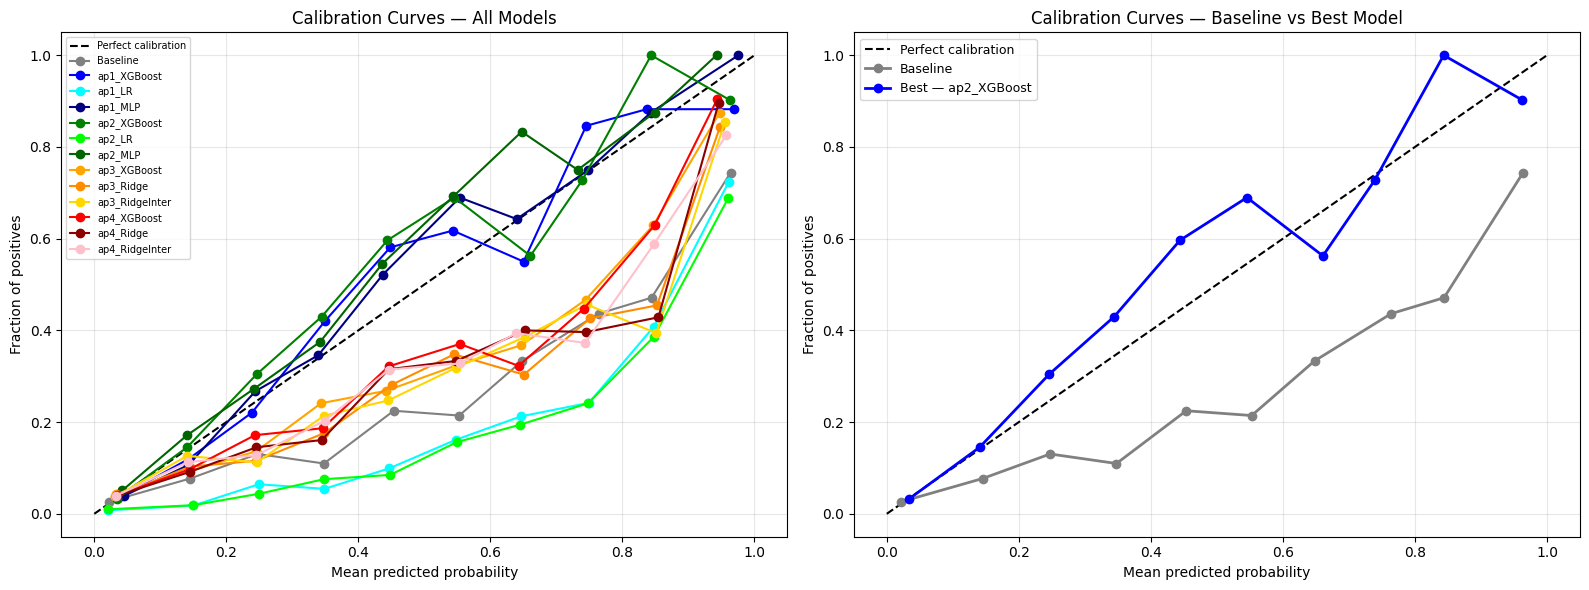


Calibration curves saved to: ./outputs/calibration_curves.png


In [10]:
# ============================================================
# CELL 10 — Final Comparison & Calibration Curves
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# ── Load ALL saved predictions ────────────────────────────────
probs_baseline       = np.load(f"{SAVE_DIR}/probs_baseline.npy")
probs_ap1_XGBoost    = np.load(f"{SAVE_DIR}/probs_ap1_XGBoost.npy")
probs_ap1_LR         = np.load(f"{SAVE_DIR}/probs_ap1_LR.npy")
probs_ap1_MLP        = np.load(f"{SAVE_DIR}/probs_ap1_MLP.npy")
probs_ap2_XGBoost    = np.load(f"{SAVE_DIR}/probs_ap2_XGBoost.npy")
probs_ap2_LR         = np.load(f"{SAVE_DIR}/probs_ap2_LR.npy")
probs_ap2_MLP        = np.load(f"{SAVE_DIR}/probs_ap2_MLP.npy")
probs_ap3_XGBoost    = np.load(f"{SAVE_DIR}/probs_ap3_XGBoost.npy")
probs_ap3_Ridge      = np.load(f"{SAVE_DIR}/probs_ap3_Ridge.npy")
probs_ap3_RidgeInter = np.load(f"{SAVE_DIR}/probs_ap3_RidgeInter.npy")
probs_ap4_XGBoost    = np.load(f"{SAVE_DIR}/probs_ap4_XGBoost.npy")
probs_ap4_Ridge      = np.load(f"{SAVE_DIR}/probs_ap4_Ridge.npy")
probs_ap4_RidgeInter = np.load(f"{SAVE_DIR}/probs_ap4_RidgeInter.npy")
y_test               = np.load(f"{SAVE_DIR}/y_test.npy")

all_probs = {
    'Baseline'        : probs_baseline,
    'ap1_XGBoost'     : probs_ap1_XGBoost,
    'ap1_LR'          : probs_ap1_LR,
    'ap1_MLP'         : probs_ap1_MLP,
    'ap2_XGBoost'     : probs_ap2_XGBoost,
    'ap2_LR'          : probs_ap2_LR,
    'ap2_MLP'         : probs_ap2_MLP,
    'ap3_XGBoost'     : probs_ap3_XGBoost,
    'ap3_Ridge'       : probs_ap3_Ridge,
    'ap3_RidgeInter'  : probs_ap3_RidgeInter,
    'ap4_XGBoost'     : probs_ap4_XGBoost,
    'ap4_Ridge'       : probs_ap4_Ridge,
    'ap4_RidgeInter'  : probs_ap4_RidgeInter,
}

# ── Identify best complex model (by OOF Brier Score on Train) ──
y_train_arr = train_df[TARGET_COLUMN].values
complex_oof_probs = {}
for name in all_probs.keys():
    if name == 'Baseline':
        continue
    oof_file = f"{SAVE_DIR}/probs_{name}_oof_train.npy"
    complex_oof_probs[name] = np.load(oof_file)

best_complex_name = min(
    complex_oof_probs.keys(),
    key=lambda x: brier_score_loss(y_train_arr, complex_oof_probs[x])
)
probs_best_complex = all_probs[best_complex_name]
best_oof_brier = brier_score_loss(y_train_arr, complex_oof_probs[best_complex_name])
test_brier = brier_score_loss(y_test, probs_best_complex)

# ── Compute metrics for all models ───────────────────────────
print("=" * 60)
print("FINAL COMPARISON — ALL APPROACHES VS BASELINE")
print("=" * 60)

baseline_ll    = log_loss(y_test, probs_baseline)
baseline_auc   = roc_auc_score(y_test, probs_baseline)
baseline_brier = brier_score_loss(y_test, probs_baseline)
baseline_mae   = np.abs(probs_baseline - y_test).mean()

final_results = []
for name, probs in all_probs.items():
    ll    = log_loss(y_test, probs)
    auc   = roc_auc_score(y_test, probs)
    brier = brier_score_loss(y_test, probs)
    mae   = np.abs(probs - y_test).mean()
    final_results.append({
        'Model'          : name,
        'MAE'            : round(mae, 4),
        'Log-Loss'       : round(ll, 4),
        'AUC'            : round(auc, 4),
        'Brier Score'    : round(brier, 4),
        'MAE vs Baseline': round(baseline_mae - mae, 4),
        'LL vs Baseline' : round(baseline_ll - ll, 4),
        'AUC vs Baseline': round(auc - baseline_auc, 4),
    })

final_df = pd.DataFrame(final_results)
# Only print Baseline and the CV-selected Best Complex Model on the test set
final_df = final_df[final_df['Model'].isin(['Baseline', best_complex_name])].sort_values('MAE')
print(final_df.to_string(index=False))

# ── Improvement over baseline ─────────────────────────────────
print("\n" + "=" * 60)
print("IMPROVEMENT OVER BASELINE")
print("=" * 60)
for _, row in final_df.iterrows():
    if row['Model'] == 'Baseline':
        continue
    mae_sign = '↓' if row['MAE vs Baseline'] > 0 else '↑'
    ll_sign  = '↓' if row['LL vs Baseline'] > 0 else '↑'
    auc_sign = '↑' if row['AUC vs Baseline'] > 0 else '↓'
    print(f"\n{row['Model']}:")
    print(f"  MAE      : {baseline_mae:.4f} → {row['MAE']:.4f}       "
          f"{mae_sign} {abs(row['MAE vs Baseline']):.4f}")
    print(f"  Log-Loss : {baseline_ll:.4f} → {row['Log-Loss']:.4f}  "
          f"{ll_sign} {abs(row['LL vs Baseline']):.4f}")
    print(f"  AUC      : {baseline_auc:.4f} → {row['AUC']:.4f}      "
          f"{auc_sign} {abs(row['AUC vs Baseline']):.4f}")
    print(f"  Brier    : {baseline_brier:.4f} → {row['Brier Score']:.4f}")

print(f"\n{'='*50}")
print(f"BEST COMPLEX MODEL : {best_complex_name}")
print(f"OOF Brier Score (Train) : {best_oof_brier:.4f}")
print(f"Test Brier Score        : {test_brier:.4f}")
print(f"OOF file for Cell 12: probs_{best_complex_name}_oof_train.npy")
print(f"{'='*50}")

# ── Calibration curves ────────────────────────────────────────
print("\nPlotting calibration curves...")
plt.style.use('default')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left plot — all models
ax = axes[0]
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)

colors_all = ['gray', 'blue', 'cyan', 'navy', 'green', 'lime', 'darkgreen',
              'orange', 'darkorange', 'gold', 'red', 'darkred', 'pink']
for (name, probs), color in zip(all_probs.items(), colors_all):
    fraction_pos, mean_pred = calibration_curve(y_test, probs, n_bins=10)
    ax.plot(mean_pred, fraction_pos, marker='o', label=name,
            color=color, linewidth=1.5)

ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration Curves — All Models')
ax.legend(fontsize=7, loc='upper left')
ax.grid(True, alpha=0.3)

# Right plot — best complex model vs baseline only
ax2 = axes[1]
ax2.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)

for name, probs, color in [
    ('Baseline',                    probs_baseline,     'gray'),
    (f'Best — {best_complex_name}', probs_best_complex, 'blue'),
]:
    fraction_pos, mean_pred = calibration_curve(y_test, probs, n_bins=10)
    ax2.plot(mean_pred, fraction_pos, marker='o', label=name,
             color=color, linewidth=2)

ax2.set_xlabel('Mean predicted probability')
ax2.set_ylabel('Fraction of positives')
ax2.set_title('Calibration Curves — Baseline vs Best Model')
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/calibration_curves.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\nCalibration curves saved to: {SAVE_DIR}/calibration_curves.png")

Official file loaded : 2888 shots
Unique shooters after mapping : 280
Unique goalies after mapping  : 26

Merge results:
  Matched     : 2,577 shots
  Not matched : 315 shots  (augmented shots — expected)
  Match rate  : 89.1%

FINAL COMPARISON — OUR MODELS VS OFFICIAL xG
                       Model  Log-Loss    AUC  Brier Score  Avg xG (Goal)  Avg xG (No Goal)    Gap
      Our Best — ap2_XGBoost    0.2516 0.8742       0.0711         0.3655            0.0727 0.2929
        Official xG (League)    0.2771 0.8159       0.0796         0.3411            0.0909 0.2502
Our Baseline (Physical only)    0.2993 0.8704       0.0911         0.5957            0.1400 0.4557

IMPROVEMENT OVER OFFICIAL xG

Our Best — ap2_XGBoost:
  Log-Loss  : 0.2771 → 0.2516  ↓ better (0.0255)
  AUC       : 0.8159 → 0.8742  ↑ better (0.0583)
  Brier     : 0.0796 → 0.0711  ↓ better (0.0085)
  xG Gap    : 0.2502 → 0.2929  ↑ better (0.0427)

Our Baseline (Physical only):
  Log-Loss  : 0.2771 → 0.2993  ↑ worse (0.0222)
 

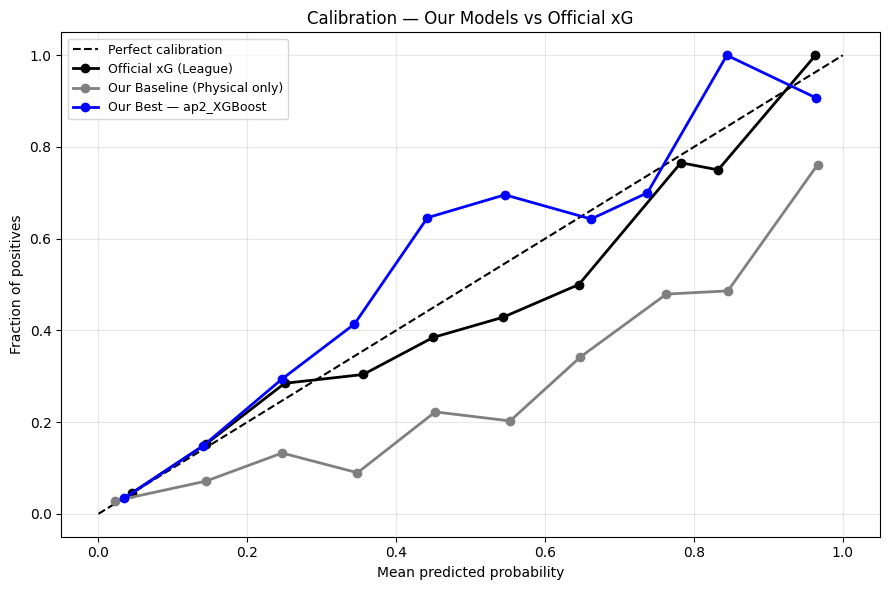


Saved to: ./outputs/calibration_vs_official_final.png


In [11]:
# ============================================================
# CELL 11 — Comparison vs Official xG
# ============================================================

import unicodedata

# ── Load files ────────────────────────────────────────────────
df_official = pd.read_csv('24-25_cleaned_test.csv')
df_official['Date'] = pd.to_datetime(df_official['Date'])

df_mapping = pd.read_excel('ligat_haal_player_match_cleaned.xlsx')

print(f"Official file loaded : {len(df_official)} shots")

# ── Build name mapping dictionary ────────────────────────────
# From mapping file
name_map = dict(zip(
    df_mapping['Player_name_shot'],
    df_mapping['player_name_performance']
))

# Add 6 missing goalies manually
manual_additions = {
    'K. Niemczycki': 'Karol Niemczycki',
    'M. Alchevski' : 'Marko Alchevski',
    'M. Zalmanovich': 'Matan Zalmanovich',
    'O. Antman'    : 'Ofek Antman',
    'S. Sluga'     : 'Simon Sluga',
    'T. Sultani'   : 'Tomas Sultani'
}
name_map.update(manual_additions)

# ── Map names in official file ────────────────────────────────
df_official['shooter_mapped'] = df_official['shooter'].map(name_map).fillna(df_official['shooter'])
df_official['goalie_mapped']  = df_official['goalie'].map(name_map).fillna(df_official['goalie'])

print(f"Unique shooters after mapping : {df_official['shooter_mapped'].nunique()}")
print(f"Unique goalies after mapping  : {df_official['goalie_mapped'].nunique()}")

# ── Decode one-hot ShotBodyPart in test_df ────────────────────
def decode_body_part(row):
    if row.get('shots_enc__shots__ShotBodyPart_Head', 0) == 1:
        return 'Head'
    elif row.get('shots_enc__shots__ShotBodyPart_Left Foot', 0) == 1:
        return 'Left Foot'
    elif row.get('shots_enc__shots__ShotBodyPart_Right Foot', 0) == 1:
        return 'Right Foot'
    else:
        return 'Unknown'

test_df['body_part'] = test_df.apply(decode_body_part, axis=1)
test_df['EventX_raw'] = test_df['shots_enc__shots__EventX']
test_df['EventY_raw'] = test_df['shots_enc__shots__EventY']

# Helper function to normalize unicode/casing (exactly like Notebook 1/2/3)
def clean_player_name(val):
    if not isinstance(val, str):
        return ""
    val = val.strip().lower()
    # Remove accents/diacritics
    nfkd_form = unicodedata.normalize('NFKD', val)
    return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

df_official['shooter_mapped_clean'] = df_official['shooter_mapped'].apply(clean_player_name)
df_official['goalie_mapped_clean'] = df_official['goalie_mapped'].apply(clean_player_name)

test_df['shooter_clean'] = test_df['shooter'].apply(clean_player_name)
test_df['goalie_clean'] = test_df['goalie'].apply(clean_player_name)

# ── Prepare official file for merge ──────────────────────────
df_official_merge = df_official.rename(columns={
    'EventX'      : 'EventX_raw',
    'EventY'      : 'EventY_raw',
    'ShotBodyPart': 'body_part',
    'Date'        : 'date'
})[['date', 'shooter_mapped_clean', 'goalie_mapped_clean',
    'EventX_raw', 'EventY_raw', 'body_part', 'xG']]

# ── Prepare test_df for merge ─────────────────────────────────
test_merge = test_df[['date', 'shooter_clean', 'goalie_clean',
                       'EventX_raw', 'EventY_raw',
                       'body_part', 'is_Goal']].copy()
test_merge['original_index'] = test_df.index

# ── Merge ─────────────────────────────────────────────────────
df_merged = test_merge.merge(
    df_official_merge,
    left_on  = ['date', 'shooter_clean', 'goalie_clean',
                'EventX_raw', 'EventY_raw', 'body_part'],
    right_on = ['date', 'shooter_mapped_clean', 'goalie_mapped_clean',
                'EventX_raw', 'EventY_raw', 'body_part'],
    how='left'
)

matched     = df_merged['xG'].notna().sum()
not_matched = df_merged['xG'].isna().sum()

print(f"\nMerge results:")
print(f"  Matched     : {matched:,} shots")
print(f"  Not matched : {not_matched:,} shots  (augmented shots — expected)")
print(f"  Match rate  : {matched/len(df_merged):.1%}")

# ── Use only matched rows ─────────────────────────────────────
df_eval     = df_merged[df_merged['xG'].notna()].copy().reset_index(drop=True)
y_eval      = df_eval['is_Goal'].values
matched_idx = df_eval['original_index'].values

probs_official  = df_eval['xG'].values
probs_base_eval = probs_baseline[matched_idx]
probs_best_eval = probs_best_complex[matched_idx]

# ── Metrics function ──────────────────────────────────────────
def compute_metrics(name, probs, y_true):
    probs       = np.clip(probs, 1e-7, 1 - 1e-7)
    ll          = log_loss(y_true, probs)
    auc         = roc_auc_score(y_true, probs)
    brier       = brier_score_loss(y_true, probs)
    avg_goal    = probs[y_true == 1].mean()
    avg_no_goal = probs[y_true == 0].mean()
    gap         = avg_goal - avg_no_goal
    return {
        'Model'           : name,
        'Log-Loss'        : round(ll, 4),
        'AUC'             : round(auc, 4),
        'Brier Score'     : round(brier, 4),
        'Avg xG (Goal)'   : round(avg_goal, 4),
        'Avg xG (No Goal)': round(avg_no_goal, 4),
        'Gap'             : round(gap, 4)
    }

# ── Run all models ────────────────────────────────────────────
models = {
    'Official xG (League)'                    : probs_official,
    'Our Baseline (Physical only)'            : probs_base_eval,
    f'Our Best — {best_complex_name}'         : probs_best_eval,
}

results    = [compute_metrics(name, probs, y_eval) for name, probs in models.items()]
results_df = pd.DataFrame(results).sort_values('Log-Loss')

# ── Print results ─────────────────────────────────────────────
print("\n" + "=" * 75)
print("FINAL COMPARISON — OUR MODELS VS OFFICIAL xG")
print("=" * 75)
print(results_df.to_string(index=False))

# ── Improvement over official xG ─────────────────────────────
official_row = results_df[results_df['Model'] == 'Official xG (League)'].iloc[0]

print("\n" + "=" * 75)
print("IMPROVEMENT OVER OFFICIAL xG")
print("=" * 75)

for _, row in results_df.iterrows():
    if row['Model'] == 'Official xG (League)':
        continue
    ll_diff    = official_row['Log-Loss'] - row['Log-Loss']
    auc_diff   = row['AUC'] - official_row['AUC']
    gap_diff   = row['Gap'] - official_row['Gap']
    brier_diff = official_row['Brier Score'] - row['Brier Score']

    print(f"\n{row['Model']}:")
    print(f"  Log-Loss  : {official_row['Log-Loss']:.4f} → {row['Log-Loss']:.4f}  "
          f"{'↓ better' if ll_diff > 0 else '↑ worse'} ({abs(ll_diff):.4f})")
    print(f"  AUC       : {official_row['AUC']:.4f} → {row['AUC']:.4f}  "
          f"{'↑ better' if auc_diff > 0 else '↓ worse'} ({abs(auc_diff):.4f})")
    print(f"  Brier     : {official_row['Brier Score']:.4f} → {row['Brier Score']:.4f}  "
          f"{'↓ better' if brier_diff > 0 else '↑ worse'} ({abs(brier_diff):.4f})")
    print(f"  xG Gap    : {official_row['Gap']:.4f} → {row['Gap']:.4f}  "
          f"{'↑ better' if gap_diff > 0 else '↓ worse'} ({abs(gap_diff):.4f})")

# ── Calibration curve ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration', linewidth=1.5)

colors = ['black', 'gray', 'blue', 'red']
for (name, probs), color in zip(models.items(), colors):
    frac_pos, mean_pred = calibration_curve(
        y_eval, np.clip(probs, 1e-7, 1 - 1e-7), n_bins=10
    )
    ax.plot(mean_pred, frac_pos, marker='o',
            label=name, color=color, linewidth=2)

ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration — Our Models vs Official xG')
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/calibration_vs_official_final.png",
            dpi=150, bbox_inches='tight')
plt.show()

print(f"\nSaved to: {SAVE_DIR}/calibration_vs_official_final.png")


### Full Metrics and xG Density Visualizations
Generate comprehensive metric comparisons and density histograms comparing Goals vs No Goals distributions.

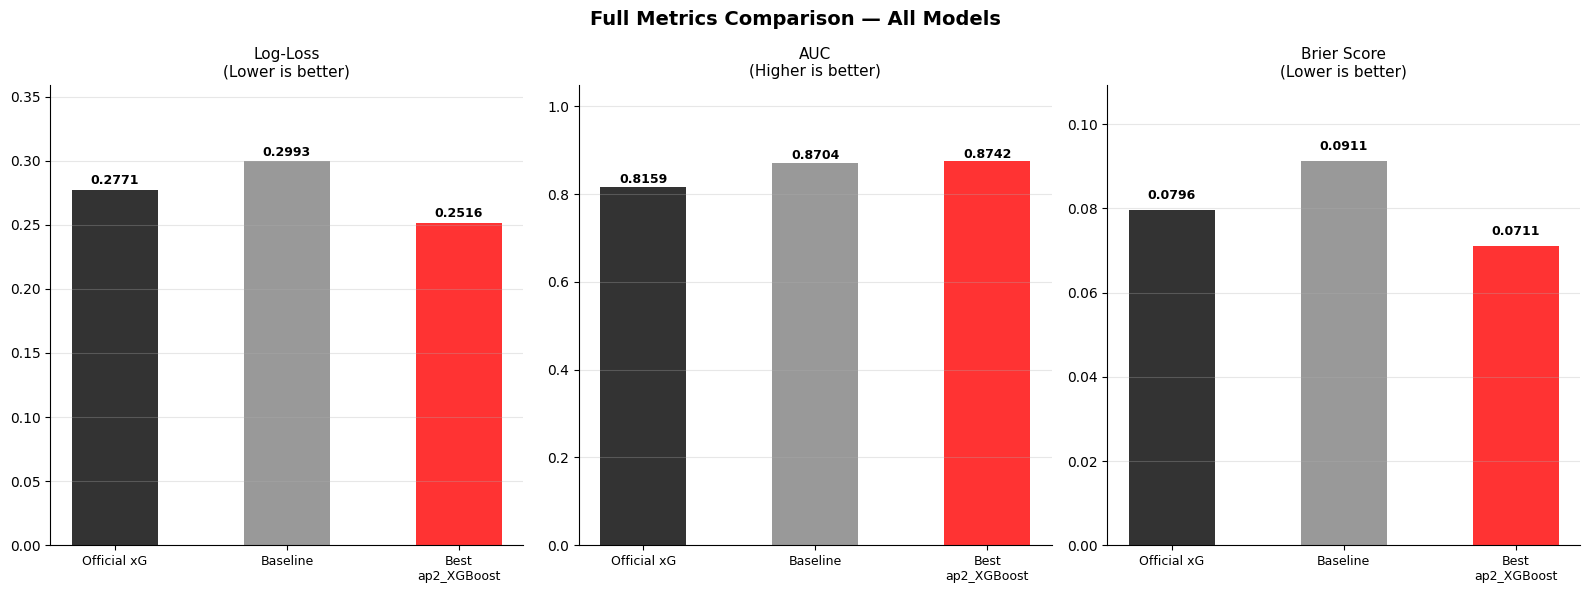

Plot 1 saved.


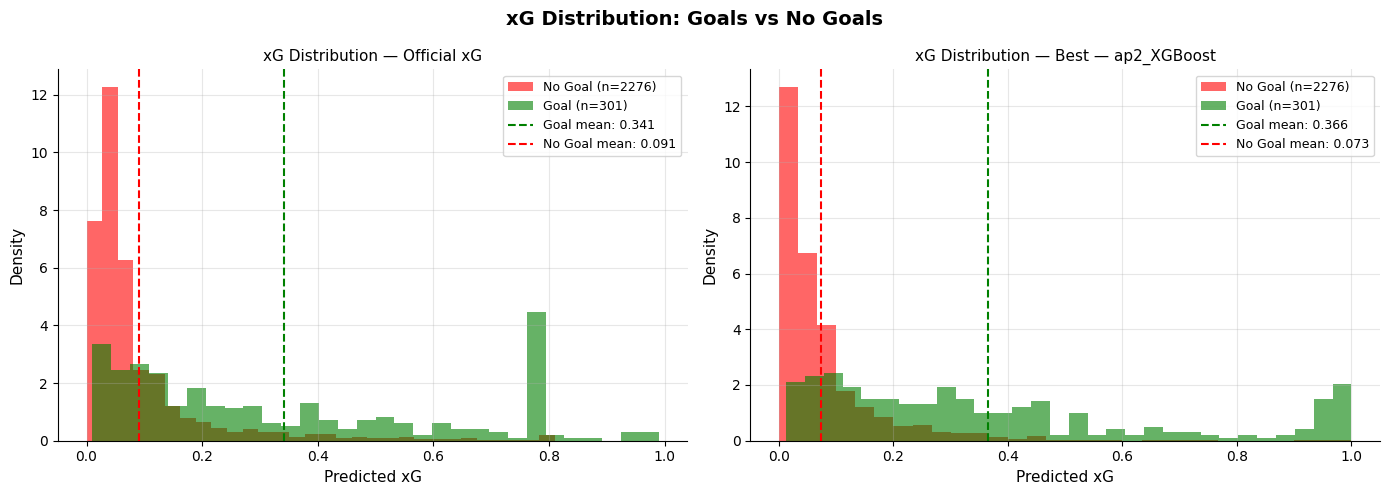

Plot 2 saved.
Pattern columns found: ['shots_enc__shots__ShotPatternOfPlay_Direct Free Kick', 'shots_enc__shots__ShotPatternOfPlay_Fast Break', 'shots_enc__shots__ShotPatternOfPlay_Free Kick Set Piece', 'shots_enc__shots__ShotPatternOfPlay_From Corner', 'shots_enc__shots__ShotPatternOfPlay_Penalty Shot', 'shots_enc__shots__ShotPatternOfPlay_Regular Play', 'shots_enc__shots__ShotPatternOfPlay_Throw-in Set Piece']

Subgroup performance by pattern of play:
            Pattern            Model    MAE  N shots  Goal rate
       Penalty Shot      Official xG 0.3304       53      0.792
       Penalty Shot         Baseline 0.0635       53      0.792
       Penalty Shot Best ap2_XGBoost 0.0986       53      0.792
       Regular Play      Official xG 0.1514     1747      0.103
       Regular Play         Baseline 0.1679     1747      0.103
       Regular Play Best ap2_XGBoost 0.1365     1747      0.103
        From Corner      Official xG 0.1543      349      0.106
        From Corner         Ba

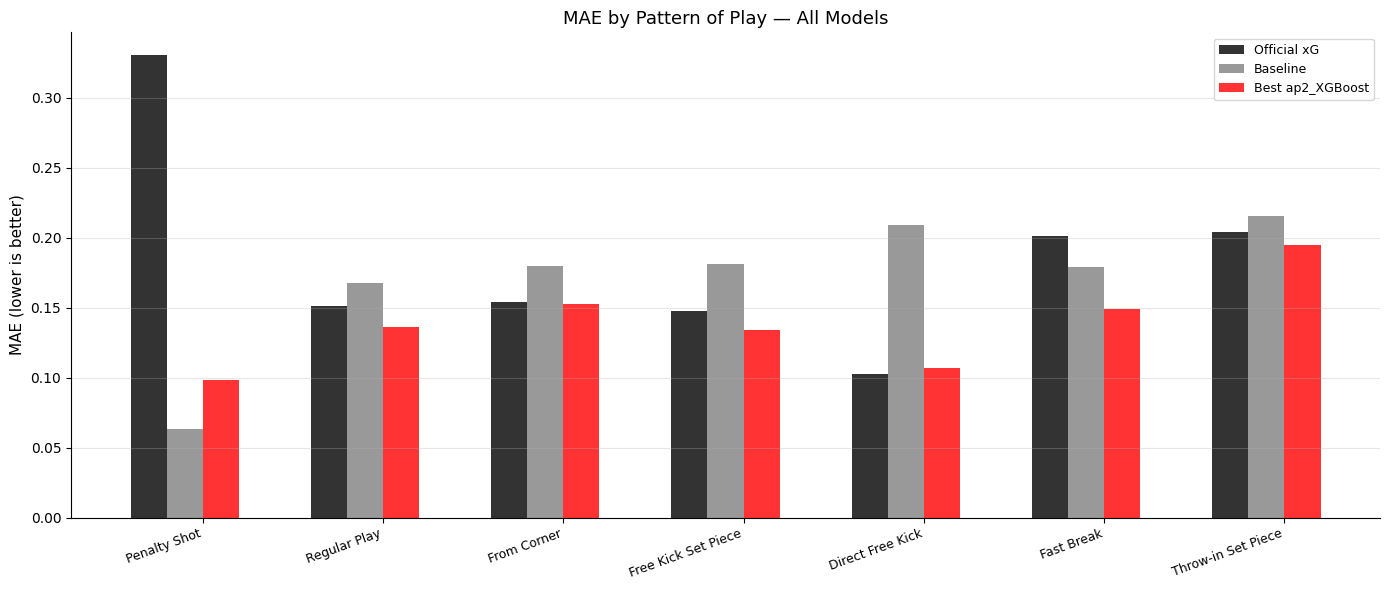

Plot 3 saved.


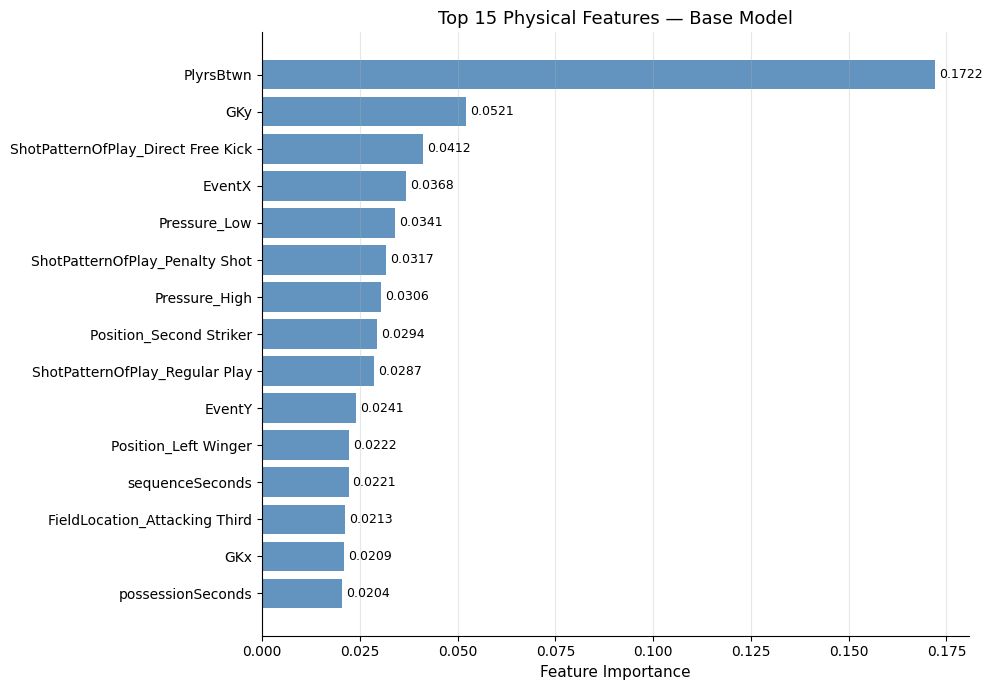

Plot 4 saved.


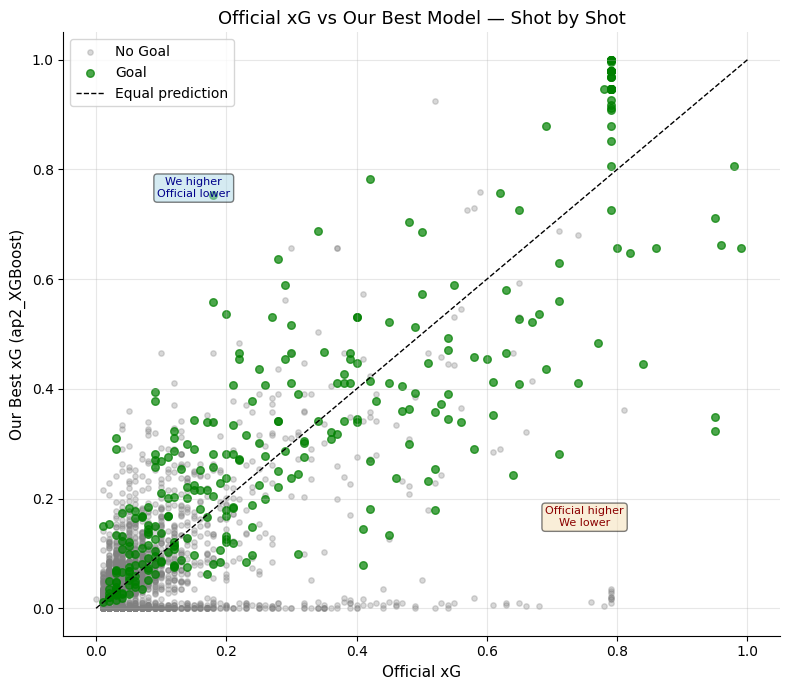

Plot 5 saved.

All 5 report plots saved to Drive:
  ./outputs/plot1_full_metrics.png
  ./outputs/plot2_xg_distribution.png
  ./outputs/plot3_subgroup_pattern.png
  ./outputs/plot4_feature_importance.png
  ./outputs/plot5_scatter_vs_official.png


In [12]:
# ============================================================
# CELL 11b — Report Visualizations
# ============================================================

import matplotlib.gridspec as gridspec


# ── Helper ────────────────────────────────────────────────────
def clip(p): return np.clip(p, 1e-7, 1 - 1e-7)

# ── Define models for comparison ─────────────────────────────
model_dict = {
    'Official xG'              : probs_official,
    'Baseline'                 : probs_base_eval,
    f'Best\n{best_complex_name}': probs_best_eval,
}

colors_map = {
    'Official xG'              : 'black',
    'Baseline'                 : 'gray',
    f'Best\n{best_complex_name}': 'red',
}

# ============================================================
# PLOT 1 — Full Metrics Comparison (3 metrics side by side)
# ============================================================

metrics_data = {}
for name, probs in model_dict.items():
    metrics_data[name] = {
        'Log-Loss'   : log_loss(y_eval, clip(probs)),
        'AUC'        : roc_auc_score(y_eval, probs),
        'Brier Score': brier_score_loss(y_eval, probs)
    }

metric_names  = ['Log-Loss', 'AUC', 'Brier Score']
better_labels = ['Lower is better', 'Higher is better', 'Lower is better']
model_names   = list(model_dict.keys())
x             = np.arange(len(model_names))
width         = 0.25

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for i, (metric, better) in enumerate(zip(metric_names, better_labels)):
    ax     = axes[i]
    values = [metrics_data[m][metric] for m in model_names]
    bars   = ax.bar(x, values,
                    color=[colors_map[m] for m in model_names],
                    alpha=0.8, width=0.5)

    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.002,
                f'{val:.4f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels(model_names, fontsize=9)
    ax.set_title(f'{metric}\n({better})', fontsize=11)
    ax.set_ylim(0, max(values) * 1.2)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Full Metrics Comparison — All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot1_full_metrics.png", dpi=150, bbox_inches='tight')
plt.show()
print("Plot 1 saved.")

# ============================================================
# PLOT 2 — xG Distribution: Goals vs No Goals
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


plot2_models = {
    'Official xG'             : probs_official,
    f'Best — {best_complex_name}': probs_best_eval
}

for ax, (name, probs) in zip(axes, plot2_models.items()):
    goals    = probs[y_eval == 1]
    no_goals = probs[y_eval == 0]

    ax.hist(no_goals, bins=30, alpha=0.6, color='red',
            label=f'No Goal (n={len(no_goals)})', density=True)
    ax.hist(goals, bins=30, alpha=0.6, color='green',
            label=f'Goal (n={len(goals)})', density=True)

    ax.axvline(goals.mean(),    color='green', linestyle='--',
               linewidth=1.5, label=f'Goal mean: {goals.mean():.3f}')
    ax.axvline(no_goals.mean(), color='red',   linestyle='--',
               linewidth=1.5, label=f'No Goal mean: {no_goals.mean():.3f}')

    ax.set_xlabel('Predicted xG', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.set_title(f'xG Distribution — {name}', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('xG Distribution: Goals vs No Goals', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot2_xg_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("Plot 2 saved.")

# ============================================================
# PLOT 3 — Subgroup Performance by Pattern of Play
# ============================================================

# Fix 1: only take the 7 original pattern columns, not interaction columns
pattern_cols = [c for c in test_df.columns
                if 'ShotPatternOfPlay' in c
                and 'inter_' not in c
                and 'style' not in c]

print(f"Pattern columns found: {pattern_cols}")

def decode_pattern(row):
    for col in pattern_cols:
        if row[col] == 1:
            return col.replace('shots_enc__shots__ShotPatternOfPlay_', '')
    return 'Unknown'

test_df['pattern'] = test_df.apply(decode_pattern, axis=1)
df_eval['pattern'] = test_df.loc[matched_idx, 'pattern'].values

subgroup_results = []
for pattern in df_eval['pattern'].unique():
    mask  = df_eval['pattern'].values == pattern
    y_sub = y_eval[mask]

    if y_sub.sum() < 5:
        continue

    for name, probs in model_dict.items():
        p_sub  = probs[mask]
        mae    = np.abs(p_sub - y_sub).mean()
        subgroup_results.append({
            'Pattern'  : pattern,
            'Model'    : name.replace('\n', ' '),
            'MAE'      : round(mae, 4),
            'N shots'  : int(mask.sum()),
            'Goal rate': round(y_sub.mean(), 3)
        })

subgroup_df = pd.DataFrame(subgroup_results)
print("\nSubgroup performance by pattern of play:")
print(subgroup_df.to_string(index=False))

# Plot subgroup Log-Loss
patterns     = subgroup_df['Pattern'].unique()
model_labels = subgroup_df['Model'].unique()
x            = np.arange(len(patterns))
width        = 0.2
colors_sub   = ['black', 'gray', 'red']

fig, ax = plt.subplots(figsize=(14, 6))
for i, (model, color) in enumerate(zip(model_labels, colors_sub)):
    vals = []
    for p in patterns:
        row = subgroup_df[(subgroup_df['Pattern'] == p) &
                          (subgroup_df['Model'] == model)]['MAE'].values
        vals.append(row[0] if len(row) > 0 else 0)
    ax.bar(x + i * width, vals, width=width,
           label=model, color=color, alpha=0.8)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(patterns, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('MAE (lower is better)', fontsize=11)
ax.set_title('MAE by Pattern of Play — All Models', fontsize=13)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot3_subgroup_pattern.png", dpi=150, bbox_inches='tight')
plt.show()
print("Plot 3 saved.")

# ============================================================
# PLOT 4 — Feature Importance (Top 15)
# ============================================================

feature_importance_full = pd.Series(
    final_base_model.feature_importances_,
    index=PHYSICAL_FEATURES
).sort_values(ascending=True).tail(15)

# Clean feature names for display
clean_names = [name.replace('shots_enc__shots__', '')
               for name in feature_importance_full.index]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(clean_names, feature_importance_full.values,
               color='steelblue', alpha=0.85)

for bar, val in zip(bars, feature_importance_full.values):
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=9)

ax.set_xlabel('Feature Importance', fontsize=11)
ax.set_title('Top 15 Physical Features — Base Model', fontsize=13)
ax.grid(axis='x', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot4_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()
print("Plot 4 saved.")

# ============================================================
# PLOT 5 — Actual vs Predicted Scatter
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))

goals    = y_eval == 1
no_goals = y_eval == 0

ax.scatter(probs_official[no_goals], probs_best_eval[no_goals],
           alpha=0.3, color='gray', s=15, label='No Goal')
ax.scatter(probs_official[goals], probs_best_eval[goals],
           alpha=0.7, color='green', s=30, label='Goal')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Equal prediction')
ax.set_xlabel('Official xG', fontsize=11)
ax.set_ylabel(f'Our Best xG ({best_complex_name})', fontsize=11)
ax.set_title(f'Official xG vs Our Best Model — Shot by Shot', fontsize=13)

ax.legend(fontsize=10)
ax.grid(alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


# Add quadrant annotations
ax.text(0.75, 0.15, 'Official higher\nWe lower',
        ha='center', fontsize=8, color='darkred',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
ax.text(0.15, 0.75, 'We higher\nOfficial lower',
        ha='center', fontsize=8, color='darkblue',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot5_scatter_vs_official.png", dpi=150, bbox_inches='tight')
plt.show()
print("Plot 5 saved.")

# ── Final summary ─────────────────────────────────────────────
print("\n" + "=" * 45)
print("All 5 report plots saved to Drive:")
print(f"  {SAVE_DIR}/plot1_full_metrics.png")
print(f"  {SAVE_DIR}/plot2_xg_distribution.png")
print(f"  {SAVE_DIR}/plot3_subgroup_pattern.png")
print(f"  {SAVE_DIR}/plot4_feature_importance.png")
print(f"  {SAVE_DIR}/plot5_scatter_vs_official.png")



### Meta Model Decision Tree
Train a Decision Tree Classifier to segment shot situations and decide when to use the Baseline model vs the Best Complex model.

Meta features built: 43
Loaded OOF predictions — best complex: ap2_XGBoost
Grouping by 21 features across 26790 shots...

Total subgroups found           : 66
Subgroups where Baseline wins    : 16
Subgroups where Best Complex wins: 50
    n_shots  goal_rate  brier_base  brier_complex  brier_diff
25       89      0.202      0.1400         0.1679     -0.0279
37       74      0.095      0.0585         0.0733     -0.0148
49       99      0.101      0.0786         0.0912     -0.0126
31       79      0.089      0.0522         0.0645     -0.0123
50       65      0.138      0.0984         0.1093     -0.0109
27      179      0.782      0.0251         0.0338     -0.0087
26      197      0.782      0.0222         0.0302     -0.0080
48       49      0.082      0.0508         0.0587     -0.0079
61       79      0.228      0.1123         0.1201     -0.0078
46       99      0.091      0.0745         0.0813     -0.0068

Shots used for meta model training : 24,810
  Label 0 (Baseline)     : 2,357 (9.5%

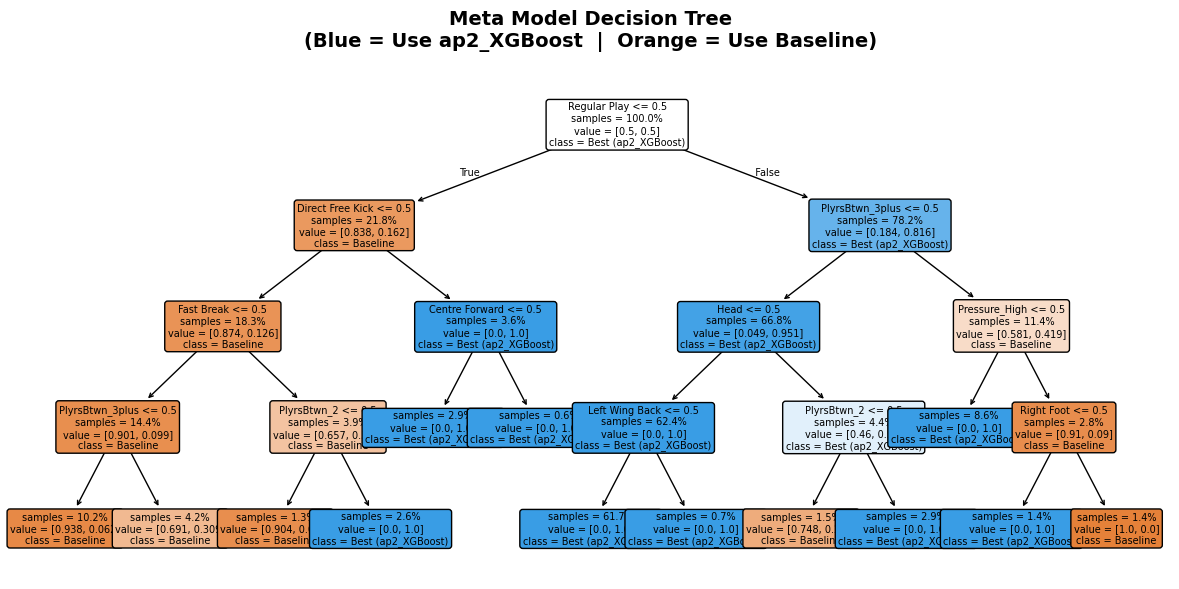


Decision Tree Rules:
|--- Regular Play <= 0.50
|   |--- Direct Free Kick <= 0.50
|   |   |--- Fast Break <= 0.50
|   |   |   |--- PlyrsBtwn_3plus <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- PlyrsBtwn_3plus >  0.50
|   |   |   |   |--- class: 0
|   |   |--- Fast Break >  0.50
|   |   |   |--- PlyrsBtwn_2 <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- PlyrsBtwn_2 >  0.50
|   |   |   |   |--- class: 1
|   |--- Direct Free Kick >  0.50
|   |   |--- Centre Forward <= 0.50
|   |   |   |--- class: 1
|   |   |--- Centre Forward >  0.50
|   |   |   |--- class: 1
|--- Regular Play >  0.50
|   |--- PlyrsBtwn_3plus <= 0.50
|   |   |--- Head <= 0.50
|   |   |   |--- Left Wing Back <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Left Wing Back >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Head >  0.50
|   |   |   |--- PlyrsBtwn_2 <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- PlyrsBtwn_2 >  0.50
|   |   |   |   |--- class: 1
|   |--- PlyrsBtwn_3plus >  0.50
| 

In [13]:
# ============================================================
# CELL 12 — Meta Model (Subgroup MAE)
# ============================================================

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree


# ── Step 1: Build meta features ───────────────────────────────
def build_meta_features(df):
    meta = pd.DataFrame(index=df.index)

    for c in df.columns:
        if 'shots_enc__shots__Position_' in c and 'inter_' not in c:
            meta[c.replace('shots_enc__shots__', '')] = df[c]

    for c in df.columns:
        if 'ShotPatternOfPlay' in c and 'inter_' not in c and 'style' not in c:
            meta[c.replace('shots_enc__shots__', '')] = df[c]

    for c in df.columns:
        if 'FieldLocation' in c and 'inter_' not in c:
            meta[c.replace('shots_enc__shots__', '')] = df[c]

    for c in df.columns:
        if 'FieldWidth' in c and 'inter_' not in c:
            meta[c.replace('shots_enc__shots__', '')] = df[c]

    for c in df.columns:
        if 'ShotBodyPart' in c and 'inter_' not in c and 'style' not in c:
            meta[c.replace('shots_enc__shots__', '')] = df[c]

    for c in df.columns:
        if 'Pressure_' in c and 'inter_' not in c and 'style' not in c:
            meta[c.replace('shots_enc__shots__', '')] = df[c]

    plyrs = df['shots_enc__shots__PlyrsBtwn']
    meta['PlyrsBtwn_0']     = (plyrs == 0).astype(int)
    meta['PlyrsBtwn_1']     = (plyrs == 1).astype(int)
    meta['PlyrsBtwn_2']     = (plyrs == 2).astype(int)
    meta['PlyrsBtwn_3plus'] = (plyrs >= 3).astype(int)

    return meta

X_meta_train = build_meta_features(train_df)
X_meta_test  = build_meta_features(test_df)
META_FEATURES = X_meta_train.columns.tolist()
print(f"Meta features built: {len(META_FEATURES)}")

# ── Step 2: Load OOF predictions ──────────────────────────────
complex_train_probs = np.load(f"{SAVE_DIR}/probs_{best_complex_name}_oof_train.npy")
base_train_probs    = np.load(f"{SAVE_DIR}/probs_baseline_oof_train.npy")
y_train_vals        = train_df[TARGET_COLUMN].values
print(f"Loaded OOF predictions — best complex: {best_complex_name}")

# ── Step 3: Subgroup Brier comparison on train set ──────────────
group_cols = (
    [c for c in META_FEATURES if 'ShotPatternOfPlay' in c] +
    [c for c in META_FEATURES if 'ShotBodyPart' in c] +
    [c for c in META_FEATURES if 'FieldLocation' in c] +
    [c for c in META_FEATURES if 'Pressure_' in c] +
    ['PlyrsBtwn_0', 'PlyrsBtwn_1', 'PlyrsBtwn_2', 'PlyrsBtwn_3plus']
)

train_meta_df                  = X_meta_train.copy()
train_meta_df['y']             = y_train_vals
train_meta_df['base_prob']     = base_train_probs
train_meta_df['complex_prob']  = complex_train_probs

print(f"Grouping by {len(group_cols)} features across {len(train_meta_df)} shots...")

subgroup_results = []
for name, group in train_meta_df.groupby(group_cols):
    if len(group) < 30:
        continue
    if group['y'].sum() < 3:
        continue

    y_grp       = group['y'].values
    base_grp    = group['base_prob'].values
    complex_grp = group['complex_prob'].values

    brier_base    = np.mean((base_grp    - y_grp) ** 2)
    brier_complex = np.mean((complex_grp - y_grp) ** 2)

    label = 1 if brier_complex < brier_base else 0

    subgroup_results.append({
        'group_key'   : name,
        'n_shots'     : len(group),
        'goal_rate'   : round(y_grp.mean(), 3),
        'brier_base'    : round(brier_base, 4),
        'brier_complex' : round(brier_complex, 4),
        'brier_diff'    : round(brier_base - brier_complex, 4),
        'label'       : label,
        'indices'     : group.index.tolist()
    })

subgroup_df = pd.DataFrame(subgroup_results)

print(f"\nTotal subgroups found           : {len(subgroup_df)}")
print(f"Subgroups where Baseline wins    : {(subgroup_df['label']==0).sum()}")
print(f"Subgroups where Best Complex wins: {(subgroup_df['label']==1).sum()}")
print(subgroup_df[subgroup_df['label']==0]
      .sort_values('brier_diff')
      [['n_shots','goal_rate','brier_base','brier_complex','brier_diff']]
      .head(10).to_string())

# ── Step 4: Assign labels back to train shots ─────────────────
meta_labels_train = np.full(len(train_df), -1)
for _, row in subgroup_df.iterrows():
    for idx in row['indices']:
        meta_labels_train[idx] = row['label']

valid_mask       = meta_labels_train != -1
X_meta_train_fit = X_meta_train[valid_mask]
y_meta_train_fit = meta_labels_train[valid_mask]

print(f"\nShots used for meta model training : {valid_mask.sum():,}")
print(f"  Label 0 (Baseline)     : {(y_meta_train_fit==0).sum():,} ({(y_meta_train_fit==0).mean():.1%})")
print(f"  Label 1 (Best Complex) : {(y_meta_train_fit==1).sum():,} ({(y_meta_train_fit==1).mean():.1%})")

# ── Step 5: Train Decision Tree ───────────────────────────────
meta_tree = DecisionTreeClassifier(
    max_depth        = 4,
    min_samples_leaf = 100,
    random_state     = RANDOM_STATE,
    class_weight     = 'balanced'
)
meta_tree.fit(X_meta_train_fit, y_meta_train_fit)

print(f"\nDecision tree trained.")
print(f"  Depth reached : {meta_tree.get_depth()}")
print(f"  Leaves        : {meta_tree.get_n_leaves()}")

# ── Step 6: Apply on test set ─────────────────────────────────
meta_decisions_test = meta_tree.predict(X_meta_test)

print(f"\nMeta model decisions on test set:")
print(f"  Use Baseline     (0): {(meta_decisions_test==0).sum():,} ({(meta_decisions_test==0).mean():.1%})")
print(f"  Use Best Complex (1): {(meta_decisions_test==1).sum():,} ({(meta_decisions_test==1).mean():.1%})")

# ── Step 7: Build final meta xG ───────────────────────────────
probs_meta = np.where(
    meta_decisions_test == 1,
    probs_best_complex,
    probs_baseline
)

# ── Step 8: Evaluate on test set ──────────────────────────────
y_test_vals = test_df[TARGET_COLUMN].values

def full_metrics(name, probs, y):
    p = np.clip(probs, 1e-7, 1 - 1e-7)
    return {
        'Model'           : name,
        'Log-Loss'        : round(log_loss(y, p), 4),
        'AUC'             : round(roc_auc_score(y, probs), 4),
        'Brier Score'     : round(brier_score_loss(y, probs), 4),
        'Avg xG (Goal)'   : round(probs[y==1].mean(), 4),
        'Avg xG (No Goal)': round(probs[y==0].mean(), 4),
        'Gap'             : round(probs[y==1].mean() - probs[y==0].mean(), 4),
        'MAE'             : round(np.abs(probs - y).mean(), 4)
    }

comparison = pd.DataFrame([
    full_metrics('Baseline',                    probs_baseline,     y_test_vals),
    full_metrics(f'Best Complex ({best_complex_name})', probs_best_complex, y_test_vals),
    full_metrics('Meta Model',                  probs_meta,         y_test_vals),
])

print("\n" + "=" * 80)
print("FINAL COMPARISON — BASELINE vs BEST COMPLEX vs META MODEL")
print("=" * 80)
print(comparison.sort_values('Brier Score').to_string(index=False))


# ── Step 9: Brier Score breakdown on test set ─────────────────────────
print("\nBrier Score breakdown on test set:")
for name, probs in [('Baseline',                    probs_baseline),
                    (f'Best Complex ({best_complex_name})', probs_best_complex),
                    ('Meta Model',                  probs_meta)]:

    # For Goals (y=1)
    brier_g  = np.mean((probs[y_test_vals==1] - 1)**2)

    # For No-Goals (y=0)
    brier_ng = np.mean((probs[y_test_vals==0] - 0)**2)

    print(f"  {name:<35} Brier (Goals): {brier_g:.4f} | Brier (No-Goals): {brier_ng:.4f}")

# ── Step 10: Visualize Decision Tree ──────────────────────────
clean_feature_names = [
    f.replace('shots_enc__shots__', '')
     .replace('ShotPatternOfPlay_', '')
     .replace('ShotBodyPart_', '')
     .replace('FieldLocation_', '')
     .replace('FieldWidth_', '')
     .replace('Position_', '')
    for f in META_FEATURES
]
plt.style.use('default')
fig, ax = plt.subplots(figsize=(12, 6), facecolor='white')
ax.set_facecolor('white')

plot_tree(
    meta_tree,
    feature_names = clean_feature_names,
    class_names   = ['Baseline', f'Best ({best_complex_name})'],
    filled        = True,
    rounded       = True,
    fontsize      = 7,
    ax            = ax,
    impurity      = False,
    proportion    = True
)
plt.title(
    f'Meta Model Decision Tree\n(Blue = Use {best_complex_name}  |  Orange = Use Baseline)',
    fontsize=14, fontweight='bold', pad=20
)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/meta_model_tree.png", dpi=150, bbox_inches='tight')
plt.show()

# ── Step 11: Print text rules ──────────────────────────────────
print("\nDecision Tree Rules:")
print(export_text(meta_tree, feature_names=clean_feature_names))
print(f"\nTree saved to: {SAVE_DIR}/meta_model_tree.png")

### Brier Score Improvement by Subgroup
Analyze and plot Brier Score improvements across various subgroups (body part, pattern of play, range, pressure, defender count).

WHERE EACH MODEL WINS — Brier Score by Subgroup
           Situation  N shots  Goal rate  Brier Base  Brier Complex  Improvement   Winner
    Direct Free Kick       95      0.053      0.1026         0.0526       0.0500  Complex
              Header      467      0.094      0.1184         0.0736       0.0448  Complex
    1 player between      478      0.318      0.1675         0.1347       0.0327  Complex
           Free Kick      164      0.104      0.1117         0.0809       0.0308  Complex
        Low pressure      946      0.177      0.1126         0.0864       0.0262  Complex
  3+ players between      609      0.041      0.0619         0.0370       0.0249  Complex
    Long range (90+)      802      0.196      0.1447         0.1204       0.0243  Complex
          Fast Break      182      0.121      0.0963         0.0731       0.0233  Complex
Medium range (75-90)     1773      0.096      0.0806         0.0582       0.0224  Complex
        Regular Play     1961      0.103      0.0910

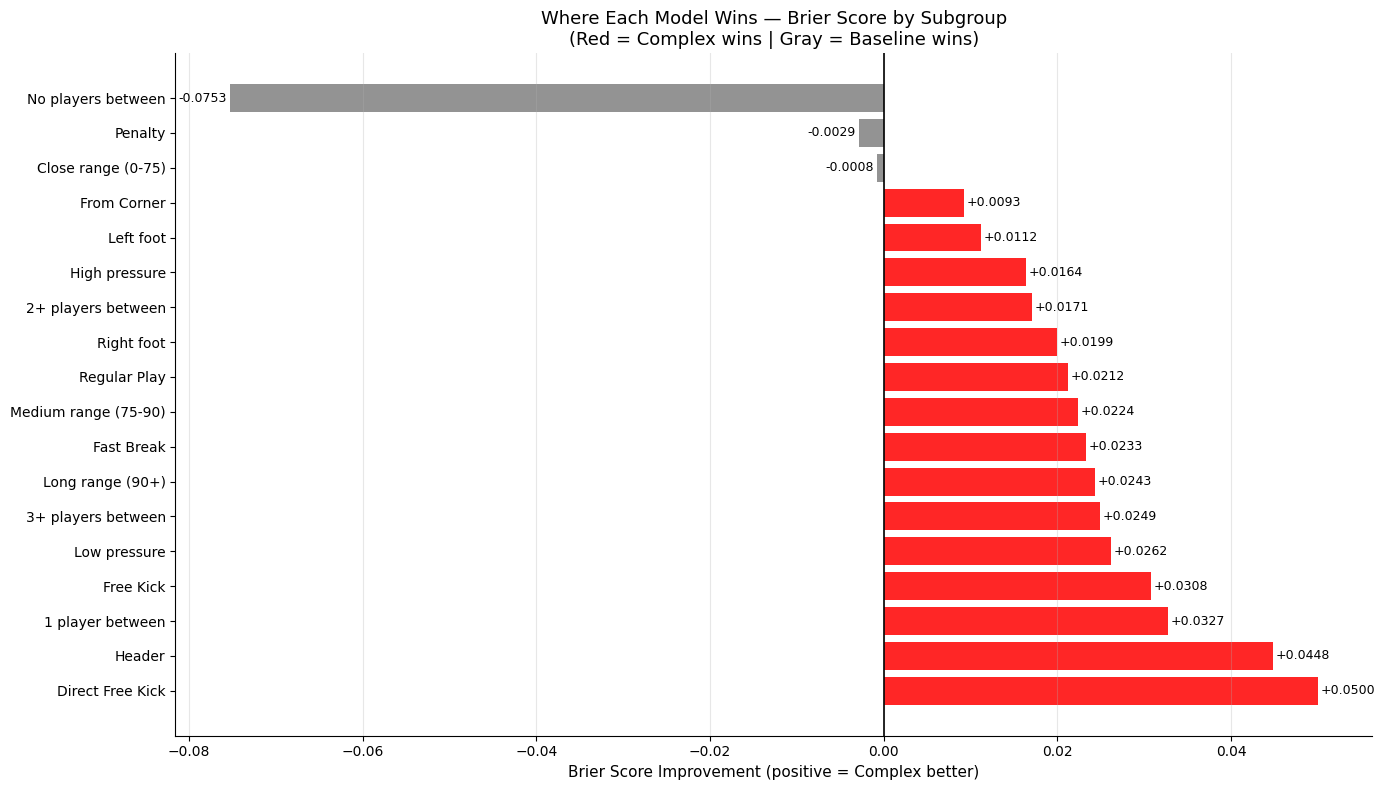


Saved to: ./outputs/plot6_subgroup_winner.png

TOP 10 SHOTS WHERE COMPLEX MODEL WINS MOST
      y_true  prob_baseline  prob_complex  complex_improvement
472        0       0.893977      0.081082             0.812895
193        0       0.870595      0.148701             0.721893
2480       0       0.832267      0.119220             0.713047
213        0       0.874816      0.178584             0.696232
2195       0       0.845879      0.151363             0.694516
1550       0       0.870643      0.180570             0.690073
1756       0       0.787160      0.098684             0.688477
2348       0       0.915367      0.229053             0.686315
1421       0       0.768984      0.090140             0.678844
1996       0       0.802655      0.128077             0.674578

TOP 10 SHOTS WHERE BASELINE WINS MOST
      y_true  prob_baseline  prob_complex  complex_improvement
609        1       0.802144      0.096466            -0.705678
2760       1       0.905735      0.214705          

In [14]:
# ============================================================
# CELL 13 — Deep Analysis: Where Each Model Wins
# ============================================================

# ── Load ───────────────────────────────────────────
y_test_vals      = np.load(f"{SAVE_DIR}/y_test.npy")
probs_baseline   = np.load(f"{SAVE_DIR}/probs_baseline.npy")
probs_complex    = np.load(f"{SAVE_DIR}/probs_{best_complex_name}.npy")

# ── Build base analysis DataFrame ────────────────────────────
analysis_df = test_df.copy().reset_index(drop=True)
analysis_df['y_true']          = y_test_vals
analysis_df['prob_baseline']   = probs_baseline
analysis_df['prob_complex']    = probs_complex
analysis_df['error_baseline']  = np.abs(probs_baseline - y_test_vals)
analysis_df['error_complex']   = np.abs(probs_complex  - y_test_vals)
analysis_df['baseline_wins']   = (analysis_df['error_baseline'] <
                                   analysis_df['error_complex']).astype(int)
analysis_df['complex_improvement'] = (analysis_df['error_baseline'] -
                                       analysis_df['error_complex'])

# ── Helper: analyze a subgroup ────────────────────────────────
def analyze_subgroup(mask, name):
    sub = analysis_df[mask]
    if len(sub) < 20:
        return None
    n          = len(sub)
    goal_rate  = sub['y_true'].mean()
    brier_base = np.mean((sub['prob_baseline'] - sub['y_true'])**2)
    brier_comp = np.mean((sub['prob_complex']  - sub['y_true'])**2)
    improvement = brier_base - brier_comp  # positive = complex better
    winner     = 'Complex' if improvement > 0 else 'Baseline'
    return {
        'Situation'    : name,
        'N shots'      : n,
        'Goal rate'    : round(goal_rate, 3),
        'Brier Base'   : round(brier_base, 4),
        'Brier Complex': round(brier_comp, 4),
        'Improvement'  : round(improvement, 4),
        'Winner'       : winner
    }

results = []

# ── Body part ─────────────────────────────────────────────────
for col, label in [
    ('shots_enc__shots__ShotBodyPart_Right Foot', 'Right foot'),
    ('shots_enc__shots__ShotBodyPart_Left Foot',  'Left foot'),
    ('shots_enc__shots__ShotBodyPart_Head',        'Header'),
]:
    if col in analysis_df.columns:
        r = analyze_subgroup(analysis_df[col] == 1, label)
        if r: results.append(r)

# ── Pattern of play ───────────────────────────────────────────
for col, label in [
    ('shots_enc__shots__ShotPatternOfPlay_Regular Play',        'Regular Play'),
    ('shots_enc__shots__ShotPatternOfPlay_Fast Break',          'Fast Break'),
    ('shots_enc__shots__ShotPatternOfPlay_From Corner',         'From Corner'),
    ('shots_enc__shots__ShotPatternOfPlay_Free Kick Set Piece', 'Free Kick'),
    ('shots_enc__shots__ShotPatternOfPlay_Penalty Shot',        'Penalty'),
    ('shots_enc__shots__ShotPatternOfPlay_Direct Free Kick',    'Direct Free Kick'),
]:
    if col in analysis_df.columns:
        r = analyze_subgroup(analysis_df[col] == 1, label)
        if r: results.append(r)

# ── Distance bins (using EventX as proxy for distance) ────────
dist = analysis_df['shots_enc__shots__EventX']
for label, mask in [
    ('Close range (0-75)',    (dist <= 75)),
    ('Medium range (75-90)',  (dist > 75)  & (dist <= 90)),
    ('Long range (90+)',      (dist > 90)),
]:
    r = analyze_subgroup(mask, label)
    if r: results.append(r)

# ── Pressure ──────────────────────────────────────────────────
for col, label in [
    ('shots_enc__shots__Pressure_High', 'High pressure'),
    ('shots_enc__shots__Pressure_Low',  'Low pressure'),
]:
    if col in analysis_df.columns:
        r = analyze_subgroup(analysis_df[col] == 1, label)
        if r: results.append(r)

# ── Players between shooter and goal ──────────────────────────
plyrs = analysis_df['shots_enc__shots__PlyrsBtwn']
for label, mask in [
    ('No players between',   (plyrs == 0)),
    ('1 player between',     (plyrs == 1)),
    ('2+ players between',   (plyrs == 2)),
    ('3+ players between',   (plyrs >= 3)),
]:
    r = analyze_subgroup(mask, label)
    if r: results.append(r)

# ── Field location ────────────────────────────────────────────
for col, label in [
    ('shots_enc__shots__FieldLocation_Center',      'Center'),
    ('shots_enc__shots__FieldLocation_Right Side',  'Right side'),
    ('shots_enc__shots__FieldLocation_Left Side',   'Left side'),
]:
    if col in analysis_df.columns:
        r = analyze_subgroup(analysis_df[col] == 1, label)
        if r: results.append(r)



# ── Build results table ───────────────────────────────────────
results_df = pd.DataFrame(results).sort_values('Improvement', ascending=False)

print("=" * 75)
print("WHERE EACH MODEL WINS — Brier Score by Subgroup")
print("=" * 75)
print(results_df.to_string(index=False))

# ── Summary counts ────────────────────────────────────────────
print(f"\nComplex wins : {(results_df['Winner']=='Complex').sum()} subgroups")
print(f"Baseline wins: {(results_df['Winner']=='Baseline').sum()} subgroups")

# ── Plot ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 8))

colors = ['red' if w == 'Complex' else 'gray'
          for w in results_df['Winner']]

bars = ax.barh(results_df['Situation'],
               results_df['Improvement'],
               color=colors, alpha=0.85)

ax.axvline(0, color='black', linewidth=1.2)

for bar, val in zip(bars, results_df['Improvement']):
    x_pos = bar.get_width() + 0.0003 if val >= 0 else bar.get_width() - 0.0003
    ha    = 'left' if val >= 0 else 'right'
    ax.text(x_pos, bar.get_y() + bar.get_height()/2,
            f'{val:+.4f}', va='center', fontsize=9, ha=ha)

ax.set_xlabel('Brier Score Improvement (positive = Complex better)', fontsize=11)
ax.set_title('Where Each Model Wins — Brier Score by Subgroup\n'
             '(Red = Complex wins | Gray = Baseline wins)', fontsize=13)
ax.grid(axis='x', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot6_subgroup_winner.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"\nSaved to: {SAVE_DIR}/plot6_subgroup_winner.png")

# ── Extreme cases ─────────────────────────────────────────────
print("\n" + "=" * 75)
print("TOP 10 SHOTS WHERE COMPLEX MODEL WINS MOST")
print("=" * 75)
top_complex = (analysis_df
               .sort_values('complex_improvement', ascending=False)
               .head(10)[['y_true','prob_baseline','prob_complex',
                           'complex_improvement']])
print(top_complex.to_string())

print("\n" + "=" * 75)
print("TOP 10 SHOTS WHERE BASELINE WINS MOST")
print("=" * 75)
top_baseline = (analysis_df
                .sort_values('complex_improvement', ascending=True)
                .head(10)[['y_true','prob_baseline','prob_complex',
                            'complex_improvement']])
print(top_baseline.to_string())

### More Analysis




In [15]:
# ── Save analysis DataFrame to Drive ─────────────────────────
analysis_df.to_csv(f"{SAVE_DIR}/analysis_df.csv", index=False)
print(f"Saved to: {SAVE_DIR}/analysis_df.csv")

Saved to: ./outputs/analysis_df.csv


Matched shots: 2577
1 — POSITIONS — Accumulated xG vs Actual Goals
                             N_shots  Goal%  Actual_Goals  xG_Complex  xG_Official  Err_Complex  Err_Official  Improvement    Winner
Position                                                                                                                            
Centre Attacking Midfielder      177   10.7            19       21.47        24.91         2.47          5.91         3.44   Complex
Central Midfielder               530    9.6            51       49.72        55.51         1.28          4.51         3.23   Complex
Right Centre Back                101    9.9            10        8.48        13.37         1.52          3.37         1.85   Complex
Defensive Midfielder              73    4.1             3        5.25         6.23         2.25          3.23         0.98   Complex
Right Back                        82    2.4             2        6.15         7.03         4.15          5.03         0.88   Complex
Le

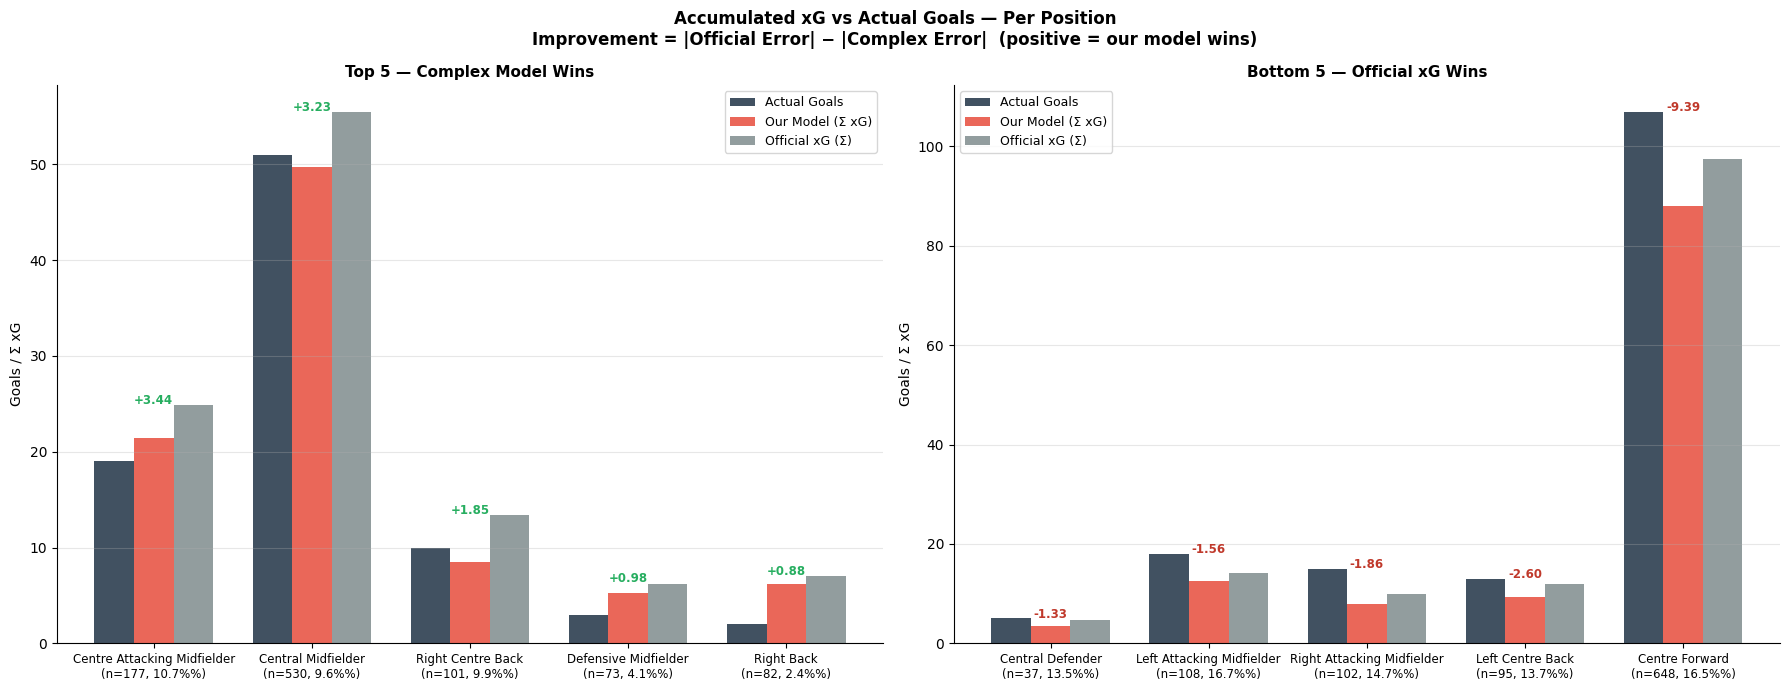

Saved: plot_positions_accumulated.png

2 — PLAYERS — Accumulated xG vs Actual Goals
                            N_shots  Goal%  Actual_Goals  xG_Complex  xG_Official  Err_Complex  Err_Official  Improvement    Winner
shooter                                                                                                                            
dor peretz                       46   13.0             6        6.33         9.04         0.33          3.04         2.71   Complex
paul arnold garita               22    4.5             1        1.96         3.90         0.96          2.90         1.94   Complex
lior refaelov                    23   21.7             5        4.41         3.05         0.59          1.95         1.36   Complex
ibrahim sangare                  21    9.5             2        2.01         3.28         0.01          1.28         1.27   Complex
timothy muzie                    23    4.3             1        1.25         2.40         0.25          1.40         1.15   

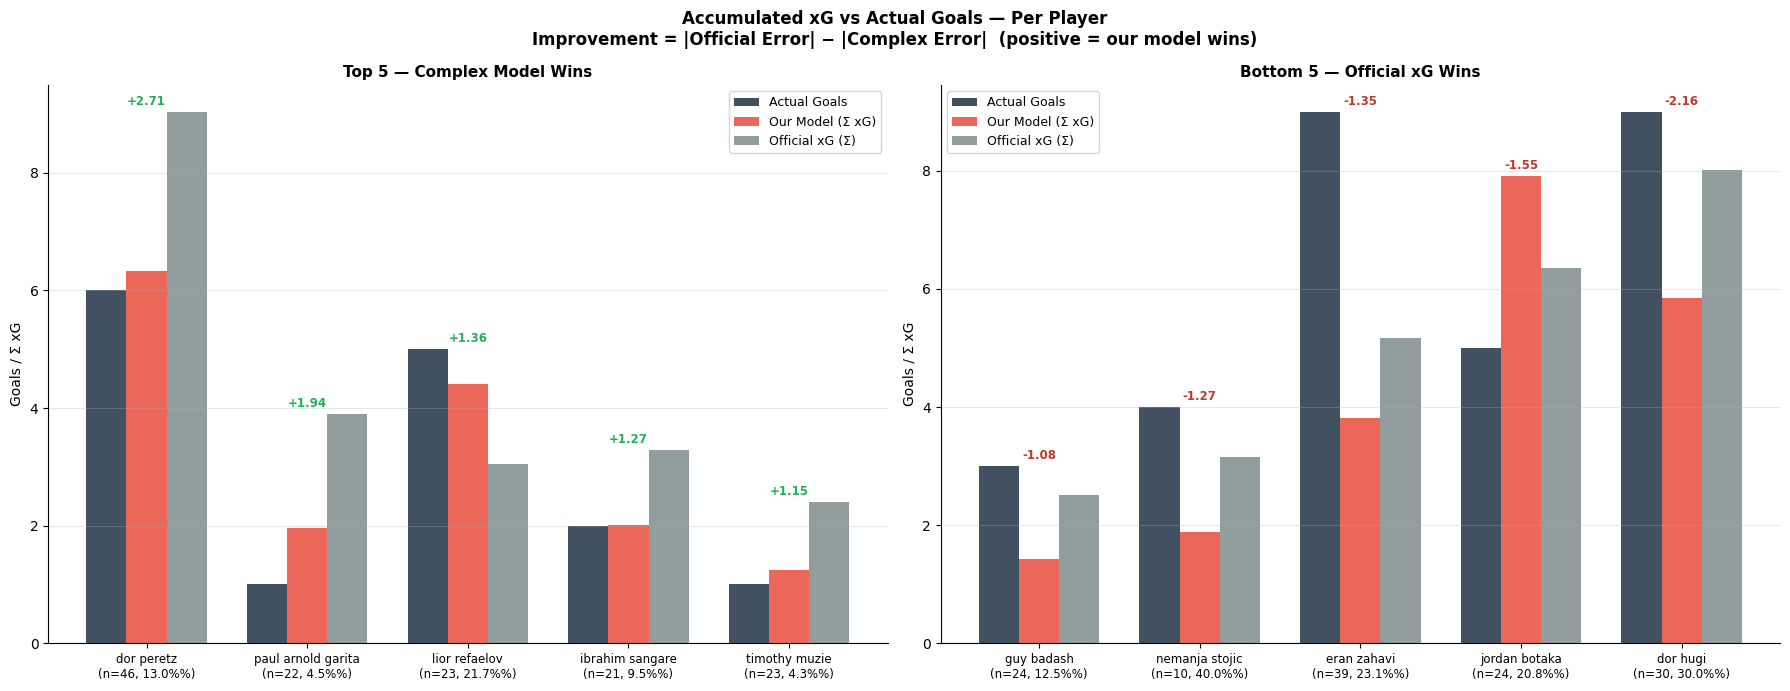

Saved: plot_players_accumulated.png

3 — TEAMS — Accumulated xG vs Actual Goals
                            N_shots  Goal%  Actual_Goals  xG_Complex  xG_Official  Err_Complex  Err_Official  Improvement    Winner
shooter_team                                                                                                                       
beitar jerusalem                250    8.8            22       26.24        29.65         4.24          7.65         3.41   Complex
maccabi bney reine              166   10.2            17       20.55        23.94         3.55          6.94         3.39   Complex
hapoel hadera                   138    9.4            13       13.27        14.83         0.27          1.83         1.56   Complex
maccabi petach tikva            158    8.2            13       13.07        14.19         0.07          1.19         1.12   Complex
maccabi netanya                 184   12.0            22       22.26        20.74         0.26          1.26         1.00   Comp

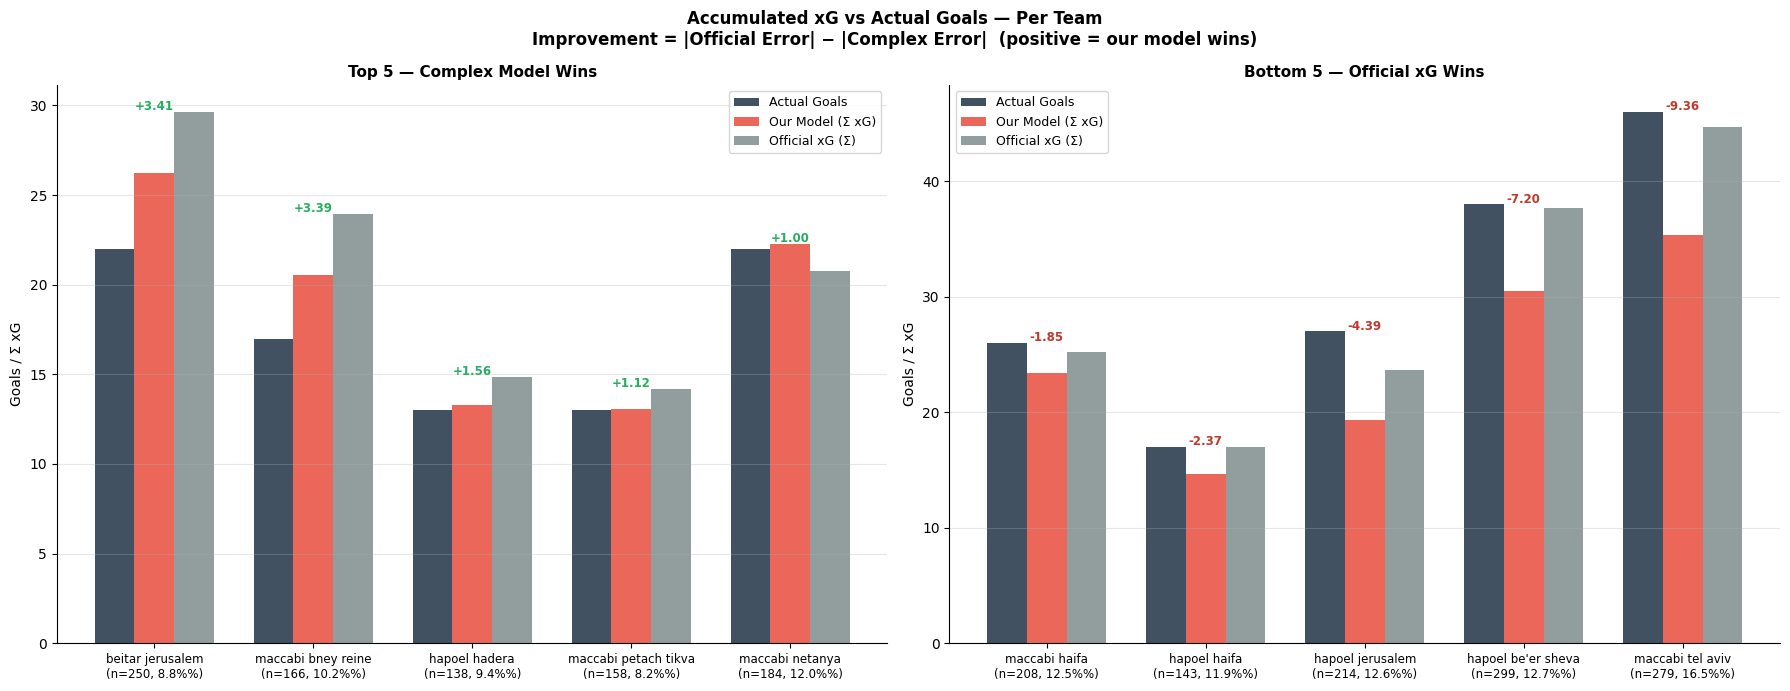

Saved: plot_teams_accumulated.png


In [16]:
# ============================================================
# CELL 14 — Accumulated xG Analysis: Positions, Players, Teams
#            Complex Model vs Official xG
# ============================================================

df_official = pd.read_csv('24-25_cleaned_test.csv')
df_mapping = pd.read_excel('ligat_haal_player_match_cleaned.xlsx')
name_map = dict(zip(
    df_mapping['Player_name_shot'],
    df_mapping['player_name_performance']
))
manual_additions = {
    'K. Niemczycki': 'Karol Niemczycki',
    'M. Alchevski' : 'Marko Alchevski',
    'M. Zalmanovich': 'Matan Zalmanovich',
    'O. Antman'    : 'Ofek Antman',
    'S. Sluga'     : 'Simon Sluga',
    'T. Sultani'   : 'Tomas Sultani'
}
name_map.update(manual_additions)

df_official['shooter_mapped'] = df_official['shooter'].map(name_map).fillna(df_official['shooter'])
df_official['goalie_mapped']  = df_official['goalie'].map(name_map).fillna(df_official['goalie'])

def clean_player_name(val):
    if not isinstance(val, str):
        return ""
    val = val.strip().lower()
    nfkd_form = unicodedata.normalize('NFKD', val)
    return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

df_official['shooter_mapped_clean'] = df_official['shooter_mapped'].apply(clean_player_name)
df_official['goalie_mapped_clean'] = df_official['goalie_mapped'].apply(clean_player_name)

analysis_df['shooter_clean'] = analysis_df['shooter'].apply(clean_player_name)
analysis_df['goalie_clean'] = analysis_df['goalie'].apply(clean_player_name)

def decode_body_part(row):
    if row.get('shots_enc__shots__ShotBodyPart_Head', 0) == 1:
        return 'Head'
    elif row.get('shots_enc__shots__ShotBodyPart_Left Foot', 0) == 1:
        return 'Left Foot'
    elif row.get('shots_enc__shots__ShotBodyPart_Right Foot', 0) == 1:
        return 'Right Foot'
    else:
        return 'Unknown'

analysis_df['body_part'] = analysis_df.apply(decode_body_part, axis=1)
analysis_df['EventX_raw'] = analysis_df['shots_enc__shots__EventX']
analysis_df['EventY_raw'] = analysis_df['shots_enc__shots__EventY']

df_official_merge = df_official.rename(columns={
    'EventX'      : 'EventX_raw',
    'EventY'      : 'EventY_raw',
    'ShotBodyPart': 'body_part',
    'Date'        : 'date'
})[['date', 'shooter_mapped_clean', 'goalie_mapped_clean',
    'EventX_raw', 'EventY_raw', 'body_part', 'xG']]

df_official_merge['date'] = pd.to_datetime(df_official_merge['date']).dt.normalize()
analysis_df['date'] = pd.to_datetime(analysis_df['date']).dt.normalize()

merged = analysis_df.merge(
    df_official_merge,
    left_on  = ['date', 'shooter_clean', 'goalie_clean', 'EventX_raw', 'EventY_raw', 'body_part'],
    right_on = ['date', 'shooter_mapped_clean', 'goalie_mapped_clean', 'EventX_raw', 'EventY_raw', 'body_part'],
    how='inner'
)

analysis_df = merged.copy().reset_index(drop=True)
analysis_df['prob_official'] = analysis_df['xG']
print(f"Matched shots: {len(analysis_df)}")

# ── Core accumulation helper ──────────────────────────────────
def accumulate_group(df, group_col, min_shots=10):
    rows = []
    for name, grp in df.groupby(group_col):
        if len(grp) < min_shots:
            continue
        actual_goals = grp['y_true'].sum()
        xg_complex   = grp['prob_complex'].sum()
        xg_official  = grp['prob_official'].sum()
        err_complex  = abs(xg_complex  - actual_goals)
        err_official = abs(xg_official - actual_goals)
        improvement  = err_official - err_complex
        rows.append({
            group_col      : name,
            'N_shots'      : len(grp),
            'Goal%'        : round(grp['y_true'].mean() * 100, 1),
            'Actual_Goals' : round(actual_goals, 1),
            'xG_Complex'   : round(xg_complex, 2),
            'xG_Official'  : round(xg_official, 2),
            'Err_Complex'  : round(err_complex, 2),
            'Err_Official' : round(err_official, 2),
            'Improvement'  : round(improvement, 2),
            'Winner'       : 'Complex' if improvement > 0 else 'Official',
        })
    return pd.DataFrame(rows).set_index(group_col).sort_values('Improvement', ascending=False)

# ── Plot helper ───────────────────────────────────────────────
def plot_accumulated(top_df, bot_df, group_label, filename, top_n=5):
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    
    for ax, subset, title in [
        (axes[0], top_df, f'Top {top_n} — Complex Model Wins'),
        (axes[1], bot_df, f'Bottom {top_n} — Official xG Wins'),
    ]:
        x = np.arange(len(subset))
        w = 0.25
        ax.bar(x - w,  subset['Actual_Goals'], w,
               label='Actual Goals',       color='#2c3e50', alpha=0.9)
        ax.bar(x,      subset['xG_Complex'],   w,
               label='Our Model (Σ xG)',   color='#e74c3c', alpha=0.85)
        ax.bar(x + w,  subset['xG_Official'],  w,
               label='Official xG (Σ)',    color='#7f8c8d', alpha=0.85)
               
        labels = [
            f"{name}\n(n={int(subset.loc[name,'N_shots'])}, "
            f"{subset.loc[name,'Goal%']}%%)"
            for name in subset.index
        ]
        ax.set_xticks(x)
        ax.set_xticklabels(labels, fontsize=8.5)
        ax.set_ylabel('Goals / Σ xG')
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.legend(fontsize=9)
        ax.grid(axis='y', alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        # Improvement annotation above bars
        for i, name in enumerate(subset.index):
            imp   = subset.loc[name, 'Improvement']
            y_top = max(subset.loc[name, 'Actual_Goals'],
                        subset.loc[name, 'xG_Complex'],
                        subset.loc[name, 'xG_Official']) + 0.12
            color = '#27ae60' if imp > 0 else '#c0392b'
            sign  = '+' if imp > 0 else ''
            ax.text(i, y_top, f'{sign}{imp:.2f}',
                    ha='center', fontsize=8.5,
                    color=color, fontweight='bold')
                    
    plt.suptitle(
        f'Accumulated xG vs Actual Goals — Per {group_label}\n'
        f'Improvement = |Official Error| − |Complex Error|  '
        f'(positive = our model wins)',
        fontsize=12, fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/{filename}", dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {filename}")

TOP_N = 5

# ══════════════════════════════════════════════════════════════
# 1 — POSITIONS
# ══════════════════════════════════════════════════════════════
pos_cols = [c for c in analysis_df.columns if 'Position_' in c and 'inter' not in c]

pos_rows = []
for col in pos_cols:
    grp = analysis_df[analysis_df[col] == 1]
    if len(grp) < 10:
        continue
    label        = col.replace('shots_enc__shots__Position_', '')
    actual_goals = grp['y_true'].sum()
    xg_complex   = grp['prob_complex'].sum()
    xg_official  = grp['prob_official'].sum()
    err_complex  = abs(xg_complex  - actual_goals)
    err_official = abs(xg_official - actual_goals)
    improvement  = err_official - err_complex
    pos_rows.append({
        'Position'     : label,
        'N_shots'      : len(grp),
        'Goal%'        : round(grp['y_true'].mean() * 100, 1),
        'Actual_Goals' : round(actual_goals, 1),
        'xG_Complex'   : round(xg_complex, 2),
        'xG_Official'  : round(xg_official, 2),
        'Err_Complex'  : round(err_complex, 2),
        'Err_Official' : round(err_official, 2),
        'Improvement'  : round(improvement, 2),
        'Winner'       : 'Complex' if improvement > 0 else 'Official',
    })

pos_df = pd.DataFrame(pos_rows).set_index('Position').sort_values('Improvement', ascending=False)

print("=" * 70)
print("1 — POSITIONS — Accumulated xG vs Actual Goals")
print("=" * 70)
print(pos_df.to_string())
print(f"\nComplex wins: {(pos_df['Winner']=='Complex').sum()} positions")
print(f"Official wins: {(pos_df['Winner']=='Official').sum()} positions")

top_pos = pos_df.head(TOP_N)
bot_pos = pos_df.tail(TOP_N)
plot_accumulated(top_pos, bot_pos, 'Position', 'plot_positions_accumulated.png', TOP_N)

# ══════════════════════════════════════════════════════════════
# 2 — PLAYERS
# ══════════════════════════════════════════════════════════════
player_df = accumulate_group(analysis_df, 'shooter', min_shots=10)

print("\n" + "=" * 70)
print("2 — PLAYERS — Accumulated xG vs Actual Goals")
print("=" * 70)
print(player_df.to_string())
print(f"\nComplex wins: {(player_df['Winner']=='Complex').sum()} players")
print(f"Official wins: {(player_df['Winner']=='Official').sum()} players")

plot_accumulated(player_df.head(TOP_N), player_df.tail(TOP_N),
                 'Player', 'plot_players_accumulated.png', TOP_N)

# ══════════════════════════════════════════════════════════════
# 3 — TEAMS
# ══════════════════════════════════════════════════════════════
team_df = accumulate_group(analysis_df, 'shooter_team', min_shots=30)

print("\n" + "=" * 70)
print("3 — TEAMS — Accumulated xG vs Actual Goals")
print("=" * 70)
print(team_df.to_string())
print(f"\nComplex wins: {(team_df['Winner']=='Complex').sum()} teams")
print(f"Official wins: {(team_df['Winner']=='Official').sum()} teams")

plot_accumulated(team_df.head(TOP_N), team_df.tail(TOP_N),
                 'Team', 'plot_teams_accumulated.png', TOP_N)
